# Desenlaces clínicos y hallazgos endoscópicos en pacientes sometidos a SpyGlass: análisis de cohorte institucional SPY-OUT (EDA)

**Autores:** Miguel Ángel Pérez Vargas [✉](mailto:vargasmiguel@uninorte.edu.co), Paula Gómez Vargas [✉](mailto:apaulag@uninorte.edu.co)

**Pregunta de investigación:** ¿cuáles son las características clínicas, endoscópicas, histológicas y los desenlaces de los pacientes sometidos a procedimiento SpyGlass en una Institución de Referencia durante el periodo de estudio?

| Bloque | Objetivo específico | Contenido |
|---|---|---|
| Calidad | Estructura de la base | carga, verificación de columnas, completitud, flujo de la cohorte |
| OE1 | Describir las características demográficas y clínicas | edad, sexo, procedencia, programación, colecistectomía, año, endoscopista, bilirrubinas al ingreso |
| OE2 | Identificar las principales indicaciones | `IND_*` (principal) e `IND2_*` (secundaria), combinaciones, grupo de indicación |
| OE3 | Describir los hallazgos endoscópicos | 7 hallazgos visuales, aspecto de la superficie, cálculos (`UBIC_*`), estenosis |
| OE4 | Describir los procedimientos terapéuticos asociados | prótesis biliar, dilatación de papila, nº de procedimientos, tiempo quirúrgico |
| OE5 | Determinar la frecuencia de biopsias dirigidas y sus resultados | `BIOPSIA_TOMADA`, `N_BIOPSIAS`, rendimiento, `RESULTADO_PATOLOGICO`, `PAT_*` |
| OE6 | Describir desenlaces inmediatos y complicaciones | complicaciones, evolución, bilirrubina ingreso → egreso y **análisis bivariado** |
| OE7 | Explorar la concordancia diagnóstica | sospecha previa vs hallazgo endoscópico vs resultado histopatológico |


## Introducción

La colangioscopía digital mediante el sistema SpyGlass permite la visualización directa de la vía biliar y constituye una herramienta de apoyo para la evaluación de diferentes alteraciones pancreatobiliares. Además de la inspección endoscópica, el procedimiento permite obtener biopsias dirigidas sobre áreas de interés, aportando información complementaria para la caracterización y el diagnóstico de las lesiones.

En este contexto, el presente proyecto se centra en el análisis de información clínica proveniente de pacientes sometidos a procedimientos con SpyGlass en una Institución de Referencia. La información disponible reúne diferentes características relacionadas con los pacientes, las indicaciones del procedimiento, los hallazgos observados y los resultados obtenidos, permitiendo estudiar el comportamiento de estas variables y las posibles relaciones existentes entre ellas.

Como primera etapa del proyecto, se desarrolla un Análisis Exploratorio de Datos (EDA) orientado a comprender la estructura y calidad de la información disponible, caracterizar la población estudiada y describir las principales variables clínicas y asociadas con el procedimiento. Asimismo, esta exploración permite identificar valores faltantes, posibles inconsistencias, distribuciones relevantes y relaciones entre variables que puedan orientar las etapas posteriores del análisis.

Los resultados del EDA constituyen la base para definir las decisiones de procesamiento y las estrategias estadísticas que resulten pertinentes de acuerdo con las características de los datos y los objetivos del proyecto.

:::{admonition} Alcance y Composición de los Datos
:class: note

Para el desarrollo de este análisis se dispone de una base de datos proporcionada por una **Institución de Referencia**, que contiene información correspondiente a pacientes sometidos a procedimientos mediante el sistema SpyGlass.

La base integra información clínica y variables relacionadas con el procedimiento, lo que permite realizar una caracterización general de los pacientes y explorar el comportamiento de los diferentes componentes registrados durante su atención.

El EDA se orientará inicialmente a evaluar la estructura general del conjunto de datos, identificar valores faltantes y posibles inconsistencias, examinar las características de las variables disponibles y describir sus principales distribuciones. Posteriormente, se explorarán las relaciones entre variables clínicas, hallazgos asociados con el procedimiento y resultados diagnósticos, de acuerdo con la información disponible en la base de datos.

Debido al carácter clínico de la información utilizada, el análisis se desarrolla preservando la confidencialidad de los datos y evitando la exposición de información que permita identificar individualmente a los pacientes.

:::

## 0. Configuración, utilidades y carga de datos

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, re, unicodedata, itertools, math, os, textwrap
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Rectangle, PathPatch
from matplotlib.path import Path as MPath
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

RUTA_PROYECTO = Path(r"C:\Users\USER\Desktop\SpyGlass")

RUTA_DATOS = RUTA_PROYECTO / "data"
RUTA_NOTEBOOKS = RUTA_PROYECTO / "notebooks"
RUTA_SRC = RUTA_PROYECTO / "src"

sys.path.insert(0, str(RUTA_SRC))

from eda_toolkit import *

HOJA = 0
CARPETA_SALIDA = RUTA_PROYECTO / "salidas_EDA"

N_ORIGINAL = 157
N_ESPERADO = 146
SEMILLA = 2026
ALFA = 0.05
UMBRAL_EDAD = 65
BIL_NORMAL = 1.2
MIN_N_GRUPO = 10

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

ruta_archivo = RUTA_DATOS / "dataset_limpio_v2.xlsx"

df_spyglass = pd.read_excel(ruta_archivo, sheet_name=HOJA)

df_spyglass = (
    df_spyglass.loc[df_spyglass["ID procedimiento"] != 153]
    .copy()
    .reset_index(drop=True)
)

N_ORIGINAL = 157
N_ESPERADO = 145

print(f"Dimensiones del dataset: {df_spyglass.shape}")

Dimensiones del dataset: (145, 81)


## 1. Calidad de los datos

Antes de desarrollar el análisis clínico, se realiza una revisión inicial de la estructura y calidad del conjunto de datos. Esta etapa permite conocer la cantidad de información disponible, identificar posibles problemas de registro y establecer las transformaciones necesarias antes de realizar análisis descriptivos o evaluar relaciones entre variables.

### 1.1 Trazabilidad de la depuración

La base de datos original contenía 157 registros. Durante la depuración se excluyeron 11 registros (7.01 %) debido a la ausencia de información sobre la edad y a la elevada proporción de valores faltantes en las demás variables.

Posteriormente, se identificó un registro correspondiente a un paciente de 13 años, el cual se excluyó por no cumplir el criterio de edad establecido en el protocolo del estudio.

En total, se excluyeron 12 registros (7.64 %), obteniendo una muestra analítica final de 145 procedimientos (92.36 % del total original).

### 1.2 Análisis de valores faltantes

In [2]:
resumen_faltantes = pd.DataFrame({
    "Variable": df_spyglass.columns,
    "Faltantes": df_spyglass.isna().sum().values,
    "Porcentaje (%)": (df_spyglass.isna().mean() * 100).values
})

resumen_faltantes = (
    resumen_faltantes
    .sort_values(["Porcentaje (%)", "Variable"], ascending=[False, True])
    .reset_index(drop=True)
)

tabla_faltantes = (
    resumen_faltantes.style
    .format({
        "Faltantes": "{:,.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .background_gradient(
        subset=["Porcentaje (%)"],
        cmap="Blues",
        vmin=0,
        vmax=100
    )
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "7px"
    })
    .set_properties(
        subset=["Variable"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption("Tabla 1. Valores faltantes por variable")
    .hide(axis="index")
)

display(tabla_faltantes)

Variable,Faltantes,Porcentaje (%)
N_CALCULOS,121,83.45%
NOTA_TAMANO_CALCULO,108,74.48%
TIPOS DE CALCULO,95,65.52%
UBICACION DE LA ESTENOSIS,76,52.41%
TAMAÑO DE CALCULO MM,69,47.59%
UBIC_COLEDOCO,39,26.90%
UBIC_COLEDOCO_DISTAL,39,26.90%
UBIC_COLEDOCO_MEDIAL,39,26.90%
UBIC_COLEDOCO_PROXIMAL,39,26.90%
UBIC_HEPATICO_COMUN,39,26.90%


En los 145 registros analizados, los mayores porcentajes de valores faltantes se encuentran en las variables relacionadas con los cálculos biliares, principalmente `N_CALCULOS` (83.45 %), `NOTA_TAMANO_CALCULO` (74.48 %) y `TIPOS DE CALCULO` (65.52 %). También se observa un porcentaje considerable de faltantes en `UBICACION DE LA ESTENOSIS` (52.41 %). Sin embargo, estas ausencias no necesariamente representan problemas de calidad de los datos, ya que algunas variables solo aplican a determinados procedimientos.

Por otra parte, las variables relacionadas con la bilirrubina presentan porcentajes de faltantes entre el 11.03 % y el 16.55 %, mientras que `INDICACIÓN SECUNDARIA` registra un 15.86 %. Estas ausencias deben tenerse en cuenta al realizar los análisis correspondientes, especialmente al definir el número de registros disponibles para cada variable.

En contraste, variables fundamentales como `EDAD`, `SEXO`, `INDICACIÓN PRINCIPAL`, `TIEMPO QUIRÚRGICO EN MINUTOS` y los principales hallazgos colangioscópicos no presentan valores faltantes. Esto permite realizar una caracterización inicial de los procedimientos sin pérdidas de información en estas variables.

En general, los valores faltantes se concentran en variables específicas y no afectan de la misma manera a todos los componentes del estudio. Por esta razón, no se realizará imputación de datos. En los análisis posteriores se utilizarán los registros con información disponible para cada variable, diferenciando, cuando sea posible, los datos no registrados de aquellos que no aplican al procedimiento.

### 1.3 Consistencia de las variables

In [3]:
hallazgos = []

def registrar(variable, problema, mascara):
    mascara = mascara.fillna(False)
    n = int(mascara.sum())

    if n > 0:
        hallazgos.append({
            "Variable": variable,
            "Verificación": problema,
            "Registros": n,
            "Porcentaje (%)": n / len(df_spyglass) * 100
        })

def numerica(columna):
    return pd.to_numeric(df_spyglass[columna], errors="coerce")

if "EDAD" in df_spyglass.columns:
    edad = numerica("EDAD")
    registrar("EDAD", "Edad fuera del rango 18–110 años", edad.notna() & ~edad.between(18, 110))
    registrar("EDAD", "Valores no numéricos", df_spyglass["EDAD"].notna() & edad.isna())

if "TIEMPO QUIRÚRGICO EN MINUTOS" in df_spyglass.columns:
    tiempo = numerica("TIEMPO QUIRÚRGICO EN MINUTOS")
    registrar("TIEMPO QUIRÚRGICO EN MINUTOS", "Tiempo menor o igual a cero", tiempo.notna() & (tiempo <= 0))
    registrar("TIEMPO QUIRÚRGICO EN MINUTOS", "Tiempo superior a 240 minutos (revisar)", tiempo > 240)
    registrar("TIEMPO QUIRÚRGICO EN MINUTOS", "Valores no numéricos", df_spyglass["TIEMPO QUIRÚRGICO EN MINUTOS"].notna() & tiempo.isna())

for col in ["N_CALCULOS", "N_BIOPSIAS", "NUMERO DE BIOPSIAS", "NUMERO DE PROCEDIMIENTOS"]:
    if col in df_spyglass.columns:
        valores = numerica(col)
        registrar(col, "Valores negativos", valores.notna() & (valores < 0))
        registrar(col, "Valores no numéricos", df_spyglass[col].notna() & valores.isna())

for col in ["BT_INGRESO", "BD_INGRESO", "BI_INGRESO", "BT_EGRESO", "BD_EGRESO", "BI_EGRESO"]:
    if col in df_spyglass.columns:
        valores = numerica(col)
        registrar(col, "Valores negativos", valores.notna() & (valores < 0))
        registrar(col, "Valores no numéricos", df_spyglass[col].notna() & valores.isna())

for momento in ["INGRESO", "EGRESO"]:
    columnas = [f"{tipo}_{momento}" for tipo in ["BT", "BD", "BI"]]

    if all(col in df_spyglass.columns for col in columnas):
        bt, bd, bi = [numerica(col) for col in columnas]

        registrar(
            f"BILIRRUBINAS_{momento}",
            "Bilirrubina directa mayor que total",
            bt.notna() & bd.notna() & (bd > bt + 0.1)
        )

        registrar(
            f"BILIRRUBINAS_{momento}",
            "Directa + indirecta difiere de total en más de 0.5 mg/dL",
            bt.notna() & bd.notna() & bi.notna() &
            ((bd + bi - bt).abs() > 0.5)
        )

for col in df_spyglass.select_dtypes(include=["object", "string"]).columns:
    serie = df_spyglass[col].astype("string")

    registrar(
        col,
        "Espacios al inicio o final",
        serie.notna() & serie.ne(serie.str.strip())
    )

    registrar(
        col,
        "Texto vacío o equivalente a faltante",
        serie.str.strip().str.upper().isin([
            "", "NAN", "NULL", "NONE", "SIN DATO",
            "SIN INFORMACION", "SIN INFORMACIÓN", "NO REGISTRA"
        ])
    )

resumen_consistencia = pd.DataFrame(
    hallazgos,
    columns=["Variable", "Verificación", "Registros", "Porcentaje (%)"]
)

if resumen_consistencia.empty:
    print("No se identificaron inconsistencias con las reglas evaluadas.")
else:
    resumen_consistencia = (
        resumen_consistencia
        .sort_values(["Registros", "Variable"], ascending=[False, True])
        .reset_index(drop=True)
    )

    display(
        resumen_consistencia.style
        .format({
            "Registros": "{:,.0f}",
            "Porcentaje (%)": "{:.2f}%"
        })
        .background_gradient(
            subset=["Registros"],
            cmap="Reds"
        )
        .set_properties(**{
            "text-align": "center",
            "border": "1px solid #D9E2F3",
            "padding": "7px"
        })
        .set_properties(
            subset=["Variable", "Verificación"],
            **{"text-align": "left"}
        )
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#17365D"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("padding", "9px")
                ]
            },
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "top"),
                    ("font-size", "15px"),
                    ("font-weight", "bold"),
                    ("color", "#17365D"),
                    ("padding", "10px")
                ]
            }
        ])
        .set_caption("Tabla 2. Verificación de consistencia de las variables")
        .hide(axis="index")
    )

Variable,Verificación,Registros,Porcentaje (%)
NUMERO DE BIOPSIAS,Valores no numéricos,117,80.69%
BILIRRUBINAS_EGRESO,Directa + indirecta difiere de total en más de 0.5 mg/dL,94,64.83%
BILIRRUBINAS_INGRESO,Directa + indirecta difiere de total en más de 0.5 mg/dL,90,62.07%
BILIRRUBINAS AL EGRESO,Espacios al inicio o final,51,35.17%
BILIRRUBINAS AL INGRESO,Espacios al inicio o final,41,28.28%
SANGRADO ESPONTANEO,Espacios al inicio o final,41,28.28%
ASPECTO DE LA SUPERFICE,Espacios al inicio o final,37,25.52%
INDICACIÓN PRINCIPAL,Espacios al inicio o final,23,15.86%
PAPILARIDAD,Espacios al inicio o final,7,4.83%
INFILTRACION,Espacios al inicio o final,6,4.14%


La revisión de consistencia de los 145 registros permitió identificar principalmente discrepancias entre las mediciones de bilirrubina, valores no numéricos y espacios adicionales en algunas variables de texto.

En `NUMERO DE BIOPSIAS`, 117 registros (80.69 %) contienen valores no numéricos. Sin embargo, esto se debe a que la variable combina cantidades con categorías como `NO`, `MULTIPLES` y `NO ESPECIFICA`, por lo que no necesariamente representa un error de registro.

Las discrepancias entre la bilirrubina total y la suma de sus fracciones directa e indirecta se identificaron en 90 registros al ingreso (62.07 %) y 94 al egreso (64.83 %). Estas diferencias requieren especial atención, ya que pueden afectar la interpretación de las mediciones de bilirrubina en los análisis posteriores.

También se encontraron espacios adicionales al inicio o al final de distintas variables de texto, principalmente en `BILIRRUBINAS AL EGRESO` (35.17 %), `BILIRRUBINAS AL INGRESO` (28.28 %) y `SANGRADO ESPONTANEO` (28.28 %). Estas diferencias corresponden a problemas de formato que pueden corregirse sin modificar el contenido de los registros.

En general, las principales observaciones corresponden a diferencias de formato y codificación, además de inconsistencias en las mediciones de bilirrubina. La revisión de algunos registros permitió comprobar que estas últimas ya estaban presentes en la información original, por lo que se decidió conservar los valores registrados sin realizar correcciones automáticas.

In [4]:
indices_revision = [1, 2, 3, 4, 8, 12, 18]

columnas = [
    "ID procedimiento",
    "BILIRRUBINAS AL INGRESO",
    "BT_INGRESO",
    "BD_INGRESO",
    "BI_INGRESO",
    "BILIRRUBINAS AL EGRESO",
    "BT_EGRESO",
    "BD_EGRESO",
    "BI_EGRESO"
]

tabla_bilirrubinas = (
    df_spyglass.loc[indices_revision, columnas]
    .set_index("ID procedimiento")
    .T
)

tabla_bilirrubinas.index.name = "Variable"

tabla_bilirrubinas = tabla_bilirrubinas.rename(index={
    "BILIRRUBINAS AL INGRESO": "Registro original - Ingreso",
    "BT_INGRESO": "Bilirrubina total - Ingreso",
    "BD_INGRESO": "Bilirrubina directa - Ingreso",
    "BI_INGRESO": "Bilirrubina indirecta - Ingreso",
    "BILIRRUBINAS AL EGRESO": "Registro original - Egreso",
    "BT_EGRESO": "Bilirrubina total - Egreso",
    "BD_EGRESO": "Bilirrubina directa - Egreso",
    "BI_EGRESO": "Bilirrubina indirecta - Egreso"
})

display(
    tabla_bilirrubinas.style
    .format(precision=2, na_rep="—")
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px",
        "white-space": "normal"
    })
    .set_properties(
        subset=pd.IndexSlice[
            ["Registro original - Ingreso", "Registro original - Egreso"], :
        ],
        **{
            "text-align": "left",
            "background-color": "#EAF1F8",
            "color": "#17365D"
        }
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption("Tabla 3. Comparación de bilirrubinas originales y procesadas")
)

ID procedimiento,2,3,4,5,9,13,19
Variable,,,,,,,
Registro original - Ingreso,"BT: 15.9, BD: 8.7, BI: 2","BT 7.2, BD 3.6, BI 1.8",BT 3.1 BD 1.3 BI 0.3,"TOTAL 0.6, BD 0, BI 0","BT 5.6, BD 2.3, BI 1.3","BT 10.32, BD 7.55, DI 2.76",BT 9.1 BD 4.1 BI 2.5
Bilirrubina total - Ingreso,15.90,7.20,3.10,0.60,5.60,10.32,9.10
Bilirrubina directa - Ingreso,8.70,3.60,1.30,0.00,2.30,7.55,4.10
Bilirrubina indirecta - Ingreso,2.00,1.80,0.30,0.00,1.30,2.76,2.50
Registro original - Egreso,BT: 4.3 BD 0.6 BI: 0.6,"BT 2.5, BD 0, BI 1","BT 0.8, BI 0.3","BT 0.7, BD 0, BI¡I 0.1","BT 2.3, BD 0, BI 0.6,",BT 7.7 BD 2 BI 1.3,"BT 1.60, BD 0.0, BI 0.30"
Bilirrubina total - Egreso,4.30,2.50,0.80,0.70,2.30,7.70,1.60
Bilirrubina directa - Egreso,0.60,0.00,—,0.00,0.00,2.00,0.00
Bilirrubina indirecta - Egreso,0.60,1.00,0.30,0.10,0.60,1.30,0.30


La comparación de siete procedimientos permitió comprobar que los valores de `BT`, `BD` y `BI` obtenidos durante el procesamiento coinciden con los registrados en las columnas originales. También se verificó que los valores no disponibles se conservaron como faltantes, como ocurre con la bilirrubina directa al egreso del procedimiento 4.

A pesar de esta correspondencia, se observaron diferencias entre la bilirrubina total y la suma de sus fracciones directa e indirecta. Por ejemplo, en el procedimiento 2, la bilirrubina total al ingreso fue de 15.9 mg/dL, mientras que la suma de las fracciones fue de 10.7 mg/dL.

Estos resultados indican que, en los procedimientos revisados, las discrepancias ya estaban presentes en la información original y no fueron introducidas durante el procesamiento. Por tanto, se conservarán los valores registrados sin realizar correcciones automáticas, teniendo en cuenta esta limitación en los análisis posteriores.

### 1.4 Duplicados y unidad de análisis

In [5]:
resumen_duplicados = pd.DataFrame({
    "Verificación": [
        "Filas completamente duplicadas",
        "ID de procedimiento duplicados",
        "ID de procedimiento únicos"
    ],
    "Resultado": [
        df_spyglass.duplicated().sum(),
        df_spyglass["ID procedimiento"].duplicated().sum(),
        df_spyglass["ID procedimiento"].nunique()
    ]
})

display(
    resumen_duplicados.style
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(subset=["Verificación"], **{"text-align": "left"})
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption("Tabla 4. Verificación de registros duplicados")
    .hide(axis="index")
)

Verificación,Resultado
Filas completamente duplicadas,0
ID de procedimiento duplicados,0
ID de procedimiento únicos,145


La revisión de los 145 registros de la muestra analítica no identificó filas completamente duplicadas ni valores repetidos en `ID procedimiento`. Se confirmó que los 145 identificadores son únicos, por lo que cada registro corresponde a un procedimiento diferente.

Debido a que la base de datos está anonimizada y no dispone de un identificador único de paciente, no es posible determinar si una misma persona fue sometida a más de un procedimiento. Por esta razón, se establece el procedimiento como unidad de análisis y los resultados se presentarán sobre un total de 145 procedimientos, sin asumir que corresponden a 145 pacientes diferentes.

## 2. Caracterización demográfica y clínica

Una vez revisada la calidad de la información, se realiza una caracterización general de los pacientes incluidos en la base de datos. En esta sección se describen inicialmente las principales características demográficas de la cohorte, con énfasis en la edad, el sexo y la procedencia de los pacientes.

### 2.1 Edad y sexo

La edad permite conocer la distribución etaria de los pacientes sometidos a SpyGlass, mientras que la distribución por sexo permite establecer la composición general de la cohorte. Ambas variables se analizan de manera conjunta como primera aproximación a las características de la población estudiada.

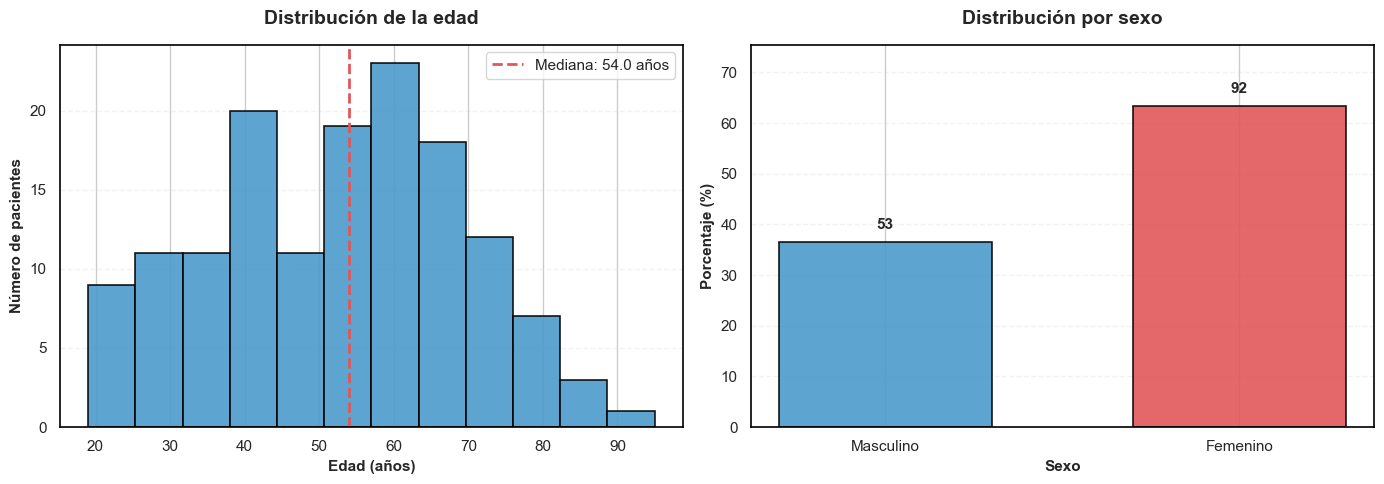

In [6]:
df_spyglass["SEXO"] = (
    df_spyglass["SEXO"]
    .astype("string")
    .str.strip()
    .str.upper()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    df_spyglass["EDAD"].dropna(),
    bins=12,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

axes[0].axvline(
    df_spyglass["EDAD"].median(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {df_spyglass['EDAD'].median():.1f} años"
)

axes[0].set_title(
    "Distribución de la edad",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel(
    "Edad (años)",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Número de pacientes",
    fontsize=11,
    fontweight="bold"
)

axes[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

axes[0].set_axisbelow(True)
axes[0].legend()

for spine in axes[0].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

sexo_counts = df_spyglass["SEXO"].value_counts()
sexo_percentages = sexo_counts / sexo_counts.sum() * 100

orden_sexo = ["MASCULINO", "FEMENINO"]
sexo_counts = sexo_counts.reindex(orden_sexo).dropna()
sexo_percentages = sexo_percentages.reindex(sexo_counts.index)

labels_sexo = [
    "Masculino" if sexo == "MASCULINO" else "Femenino"
    for sexo in sexo_counts.index
]

colors = ["#4C9ACB", "#E15759"]

bars = axes[1].bar(
    labels_sexo,
    sexo_percentages.values,
    color=colors,
    edgecolor="black",
    linewidth=1.2,
    width=0.6,
    alpha=0.9
)

for bar, count in zip(bars, sexo_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

axes[1].set_title(
    "Distribución por sexo",
    fontsize=14,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel(
    "Sexo",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Porcentaje (%)",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylim(
    0,
    max(sexo_percentages.values) + 12
)

axes[1].grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

axes[1].set_axisbelow(True)

for spine in axes[1].spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La distribución de la edad de los 145 procedimientos analizados presenta una mediana de 54 años, con una mayor concentración de edades entre los 40 y 70 años. Aunque se observan registros correspondientes a adultos jóvenes y personas mayores de 80 años, la mayoría se concentra en edades intermedias.

En cuanto al sexo, se observa un predominio femenino, con 92 procedimientos (63.45 %), frente a 53 procedimientos correspondientes al sexo masculino (36.55 %).

En general, los resultados muestran que los procedimientos SpyGlass se realizaron principalmente en personas de mediana edad, con una mayor representación del sexo femenino en la muestra estudiada.

### 2.2 Procedencia de los pacientes

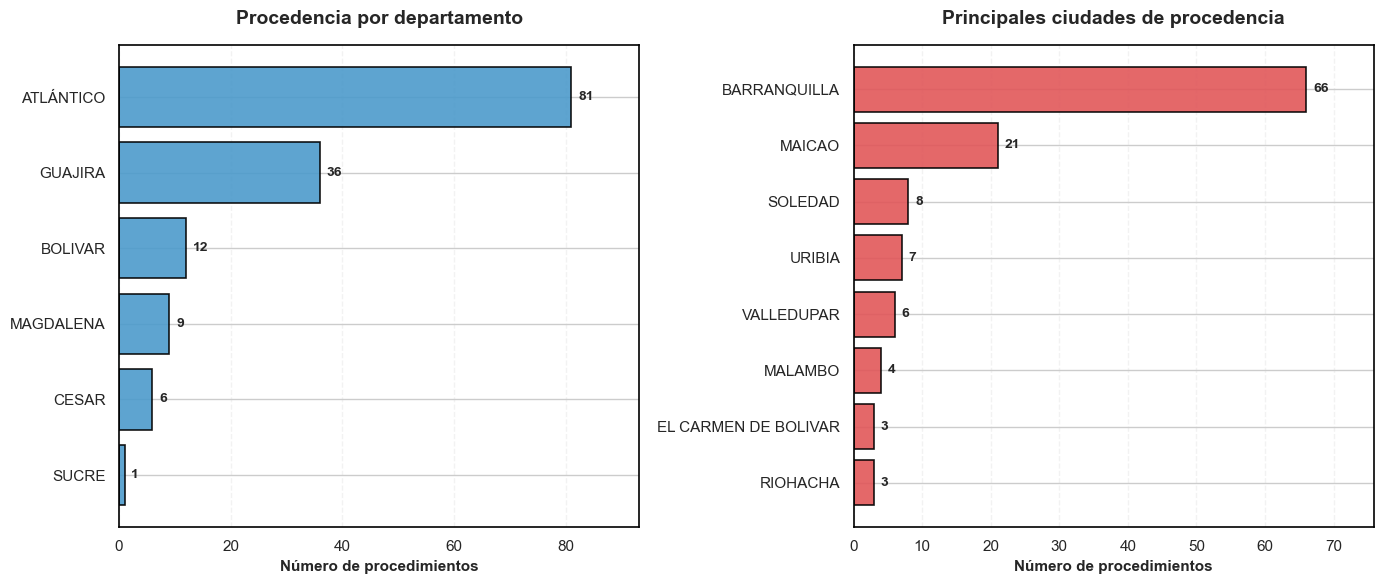

In [7]:
departamentos = (
    df_spyglass["DEPARTAMENTO"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({
        "BARRANQUILLA": "ATLÁNTICO",
        "ATLANTICO": "ATLÁNTICO"
    })
    .replace("", pd.NA)
)
ciudades = (
    df_spyglass["CUIDAD"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace("", pd.NA)
)

departamentos_plot = (
    departamentos
    .value_counts()
    .sort_values(ascending=True)
)

ciudades_plot = (
    ciudades
    .value_counts()
    .head(8)
    .sort_values(ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

datasets = [
    (
        departamentos_plot,
        "Procedencia por departamento",
        "#4C9ACB"
    ),
    (
        ciudades_plot,
        "Principales ciudades de procedencia",
        "#E15759"
    )
]

for ax, (data, titulo, color) in zip(axes, datasets):

    bars = ax.barh(
        data.index,
        data.values,
        color=color,
        edgecolor="black",
        linewidth=1.2,
        alpha=0.9
    )

    desplazamiento = max(data.max() * 0.015, 0.3)

    for bar, value in zip(bars, data.values):
        ax.text(
            bar.get_width() + desplazamiento,
            bar.get_y() + bar.get_height() / 2,
            f"{value}",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

    ax.set_title(
        titulo,
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(
        "Número de procedimientos",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel("")

    ax.set_xlim(0, data.max() * 1.15)

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La distribución geográfica de los 145 procedimientos analizados muestra una mayor concentración en el departamento del Atlántico, con 81 registros (55.86 %), seguido de La Guajira con 36 (24.83 %) y Bolívar con 12 (8.28 %). Los demás departamentos presentan una participación menor, lo que evidencia que la mayoría de los procedimientos corresponde a personas procedentes de la región Caribe colombiana.

En cuanto a las ciudades de procedencia, Barranquilla presenta la mayor frecuencia, con 66 procedimientos (45.52 %), seguida de Maicao con 21 (14.48 %) y Soledad con 8 (5.52 %). También se observa participación de municipios como Uribia, Valledupar y Malambo, aunque con frecuencias inferiores.

En general, los resultados muestran una concentración de procedimientos en Barranquilla y el Atlántico, junto con una participación importante de personas provenientes de La Guajira. Esto permite identificar la distribución geográfica de la población atendida, aunque no necesariamente refleja la distribución de la enfermedad en estos territorios.

### 2.3. Antecedentes clínicos

Se analiza el antecedente de colecistectomía en los procedimientos incluidos en el estudio, con el propósito de identificar la frecuencia de intervenciones quirúrgicas previas de la vesícula biliar en la población atendida mediante SpyGlass.

In [8]:
antecedente_colecistectomia = (
    df_spyglass["ANTECEDENTE DE COLECISTECTOMIA"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("SIN INFORMACIÓN")
)

tabla_colecistectomia = (
    antecedente_colecistectomia
    .value_counts()
    .rename_axis("Antecedente de colecistectomía")
    .reset_index(name="Frecuencia")
)

tabla_colecistectomia["Porcentaje (%)"] = (
    tabla_colecistectomia["Frecuencia"] / len(df_spyglass) * 100
)

display(
    tabla_colecistectomia.style
    .format({"Frecuencia": "{:,.0f}", "Porcentaje (%)": "{:.2f}%"})
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption("Antecedente de colecistectomía en los procedimientos analizados")
    .hide(axis="index")
)

Antecedente de colecistectomía,Frecuencia,Porcentaje (%)
NO,92,63.45%
SI,52,35.86%
SIN INFORMACIÓN,1,0.69%


De los 145 procedimientos analizados, 92 (63.45 %) corresponden a personas sin antecedente de colecistectomía, mientras que 52 (35.86 %) presentan este antecedente quirúrgico. Únicamente un registro (0.69 %) no cuenta con información disponible.

Estos resultados muestran que, aunque predomina la ausencia de colecistectomía previa, una proporción considerable de los procedimientos se realizó en personas que ya habían sido sometidas a la extracción de la vesícula biliar.

### 2.4. Características clínicas al ingreso

En esta subsección se describen los niveles de bilirrubina total, directa e indirecta registrados al ingreso, con el propósito de caracterizar el perfil bioquímico de los procedimientos incluidos en el estudio. El análisis se realiza utilizando los valores disponibles, teniendo en cuenta las inconsistencias identificadas durante la revisión de calidad de los datos.

In [9]:
columnas_bilirrubina = {
    "BT_INGRESO": "Bilirrubina total",
    "BD_INGRESO": "Bilirrubina directa",
    "BI_INGRESO": "Bilirrubina indirecta"
}

bilirrubinas_ingreso = df_spyglass[list(columnas_bilirrubina)].apply(
    pd.to_numeric, errors="coerce"
)

resumen_bilirrubinas = pd.DataFrame({
    "Variable": list(columnas_bilirrubina.values()),
    "n": bilirrubinas_ingreso.count().values,
    "Media": bilirrubinas_ingreso.mean().values,
    "DE": bilirrubinas_ingreso.std().values,
    "Mediana": bilirrubinas_ingreso.median().values,
    "Q1": bilirrubinas_ingreso.quantile(0.25).values,
    "Q3": bilirrubinas_ingreso.quantile(0.75).values,
    "Mínimo": bilirrubinas_ingreso.min().values,
    "Máximo": bilirrubinas_ingreso.max().values
})

display(
    resumen_bilirrubinas.style
    .format({
        "n": "{:.0f}",
        "Media": "{:.2f}",
        "DE": "{:.2f}",
        "Mediana": "{:.2f}",
        "Q1": "{:.2f}",
        "Q3": "{:.2f}",
        "Mínimo": "{:.2f}",
        "Máximo": "{:.2f}"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(subset=["Variable"], **{"text-align": "left"})
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption("Características bioquímicas al ingreso (mg/dL)")
    .hide(axis="index")
)

Variable,n,Media,DE,Mediana,Q1,Q3,Mínimo,Máximo
Bilirrubina total,129,5.15,5.70,3.10,0.80,7.60,0.10,27.00
Bilirrubina directa,128,2.36,3.95,0.65,0.00,3.40,0.00,25.00
Bilirrubina indirecta,126,0.95,0.80,0.70,0.30,1.50,0.00,3.20


La bilirrubina total (`BT_INGRESO`) presentó una mediana de 3.10 mg/dL y una media de 5.15 mg/dL, con valores entre 0.10 y 27.00 mg/dL. La diferencia entre la media y la mediana, junto con el valor máximo observado, sugiere una distribución asimétrica hacia la derecha, con algunos registros que presentan concentraciones considerablemente elevadas.

Por su parte, la bilirrubina directa (`BD_INGRESO`) registró una mediana de 0.65 mg/dL y una media de 2.36 mg/dL, mientras que la bilirrubina indirecta (`BI_INGRESO`) presentó valores más bajos y menos dispersos, con una mediana de 0.70 mg/dL y una media de 0.95 mg/dL.

La disponibilidad de información varió entre las tres mediciones, con 129 registros para bilirrubina total, 128 para directa y 126 para indirecta. Estos resultados deben interpretarse considerando las discrepancias entre la bilirrubina total y sus fracciones identificadas durante la revisión de consistencia de los datos.

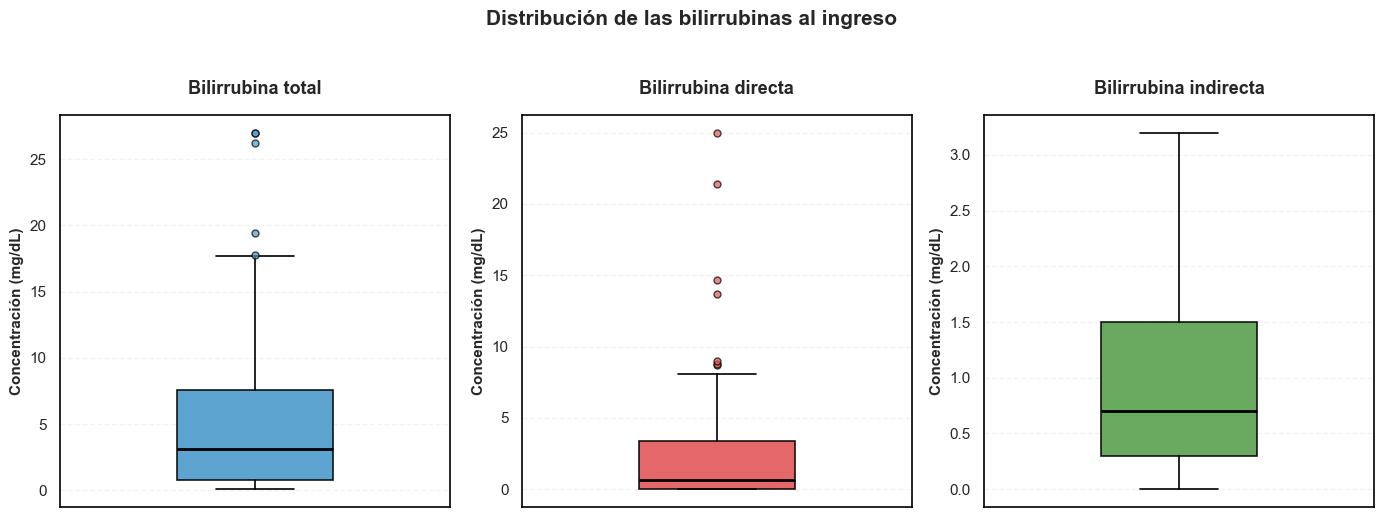

In [10]:
columnas = [
    "BT_INGRESO",
    "BD_INGRESO",
    "BI_INGRESO"
]

titulos = [
    "Bilirrubina total",
    "Bilirrubina directa",
    "Bilirrubina indirecta"
]

colores = ["#4C9ACB", "#E15759", "#59A14F"]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, columna, titulo, color in zip(axes, columnas, titulos, colores):

    datos = pd.to_numeric(
        df_spyglass[columna],
        errors="coerce"
    ).dropna()

    ax.boxplot(
        datos,
        patch_artist=True,
        widths=0.4,
        boxprops=dict(
            facecolor=color,
            edgecolor="black",
            linewidth=1.2,
            alpha=0.9
        ),
        medianprops=dict(
            color="black",
            linewidth=2
        ),
        whiskerprops=dict(
            color="black",
            linewidth=1.2
        ),
        capprops=dict(
            color="black",
            linewidth=1.2
        ),
        flierprops=dict(
            marker="o",
            markerfacecolor=color,
            markeredgecolor="black",
            markersize=5,
            alpha=0.7
        )
    )

    ax.set_title(
        titulo,
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    ax.set_ylabel(
        "Concentración (mg/dL)",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xticks([])

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)

plt.suptitle(
    "Distribución de las bilirrubinas al ingreso",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.show()

Los diagramas de caja muestran que las concentraciones de bilirrubina total y directa presentan distribuciones asimétricas hacia la derecha, con una mayor concentración de registros en valores bajos y algunos valores considerablemente elevados.

La bilirrubina total presenta una mediana de 3.10 mg/dL y varios valores atípicos superiores a 18 mg/dL, alcanzando un máximo de 27 mg/dL. Por su parte, la bilirrubina directa registra una mediana de 0.65 mg/dL y presenta valores extremos que alcanzan los 25 mg/dL.

La bilirrubina indirecta presenta una menor dispersión, con una mediana de 0.70 mg/dL y valores comprendidos entre 0 y 3.20 mg/dL, sin valores atípicos identificados mediante el criterio utilizado por el boxplot.

En general, se observa una mayor variabilidad en las concentraciones de bilirrubina total y directa. Los valores extremos no necesariamente representan errores de registro, aunque su interpretación debe considerar las inconsistencias identificadas previamente en estas variables.

## 3. Indicaciones del procedimiento 

Se analizan las principales indicaciones clínicas que motivaron la realización de los procedimientos SpyGlass. Se presentan sus frecuencias y porcentajes con el propósito de identificar los motivos más comunes de utilización de esta técnica en la muestra estudiada.

:::{admonition} Consideraciones Metodológicas sobre la Clasificación de Indicaciones
:class: note

Las indicaciones principales para la realización de SpyGlass se agruparon en categorías clínicas con el propósito de facilitar su análisis descriptivo y reducir la variabilidad en la forma de registro.

Esta clasificación se realizó a partir de la información consignada en la variable `INDICACIÓN PRINCIPAL`, **sin modificar los registros originales ni asumir la confirmación de los diagnósticos mencionados**.

En los casos donde se registraron múltiples condiciones o sospechas diagnósticas, se aplicaron criterios de agrupación consistentes, reconociendo las posibles ambigüedades. Por tanto, las categorías obtenidas representan los **motivos clínicos registrados para la realización del procedimiento**, y no necesariamente diagnósticos definitivos o confirmados histopatológicamente.

:::

### 3.1 Indiciaciones principales

In [11]:
import re
import unicodedata

def normalizar_indicacion(texto):
    if pd.isna(texto):
        return ""

    texto = str(texto).strip().upper()
    texto = "".join(
        caracter
        for caracter in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(caracter)
    )

    return re.sub(r"\s+", " ", texto)


def clasificar_indicacion(texto):
    texto = normalizar_indicacion(texto)

    if not texto:
        return "Sin información"

    if any(p in texto for p in [
        "SOSPECHA DE COLANGIOCARCINOMA",
        "TUMORAL INDETERMINADA",
        "ASPECTO TUMORAL",
        "MALIGN",
        "NEOPLAS",
        "SOSPECHA DE AMPULOMA"
    ]):
        return "Sospecha de malignidad"

    if any(p in texto for p in [
        "COLANGIOCARCINOMA",
        "KLATSKIN",
        "TUMOR DE VIA BILIAR"
    ]):
        return "Neoplasia biliar descrita"

    if any(p in texto for p in [
        "COLEDOCOL",
        "COLEDEOCOL",
        "OLEDOCOL",
        "CALCULO GRANDE EN COLEDOCO",
        "CALCULOS EN COLEDOCO",
        "COLEDOCO Y HEPATOLITIASIS"
    ]):
        return "Coledocolitiasis"

    if any(p in texto for p in [
        "HEPATOLITIASIS",
        "LITIASIS INTRAHEPATICA"
    ]):
        return "Litiasis intrahepática"

    if any(p in texto for p in [
        "ESTENOSIS BILIAR",
        "ESTENOSIS DEL HEPATICO",
        "ESTENOSIS PARCIAL",
        "LESION ESTENOSANTE",
        "LESION BILIAR",
        "OCLUSION EN LA CONFLUENCIA"
    ]):
        return "Estenosis o lesión biliar indeterminada/benigna"

    return "Otras indicaciones"


ajustes_manuales = {
    "COLEDOCOLITIASIS VS MASA": "Indicación mixta o indeterminada",
    "COLEDOCOLITIASIS VS. LESION EN AMPOLLA DE VATER": "Indicación mixta o indeterminada",
    "ESTENOSIS ESOFAGICA NEOPLASICA": "Otras indicaciones",
    "SOSPECHA DE AMPULOMA VS LESION EN CABEZA DE PANCREAS": "Otras indicaciones",
    "HEPATOPATIA CRONICA VS LESION INTRAHEPATICA": "Otras indicaciones"
}

indicaciones_normalizadas = (
    df_spyglass["INDICACIÓN PRINCIPAL"]
    .apply(normalizar_indicacion)
)

df_spyglass["INDICACION_AGRUPADA"] = (
    indicaciones_normalizadas
    .map(ajustes_manuales)
    .fillna(
        df_spyglass["INDICACIÓN PRINCIPAL"]
        .apply(clasificar_indicacion)
    )
)

resumen_indicaciones = (
    df_spyglass["INDICACION_AGRUPADA"]
    .value_counts()
    .rename_axis("Indicación")
    .reset_index(name="Procedimientos")
)

resumen_indicaciones["Porcentaje (%)"] = (
    resumen_indicaciones["Procedimientos"] / len(df_spyglass) * 100
)

display(
    resumen_indicaciones.style
    .format({
        "Procedimientos": "{:,.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Indicación"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        "Tabla 6. Distribución de las indicaciones principales agrupadas para SpyGlass"
    )
    .hide(axis="index")
)

Indicación,Procedimientos,Porcentaje (%)
Coledocolitiasis,92,63.45%
Otras indicaciones,13,8.97%
Sospecha de malignidad,12,8.28%
Estenosis o lesión biliar indeterminada/benigna,10,6.90%
Neoplasia biliar descrita,8,5.52%
Litiasis intrahepática,8,5.52%
Indicación mixta o indeterminada,2,1.38%


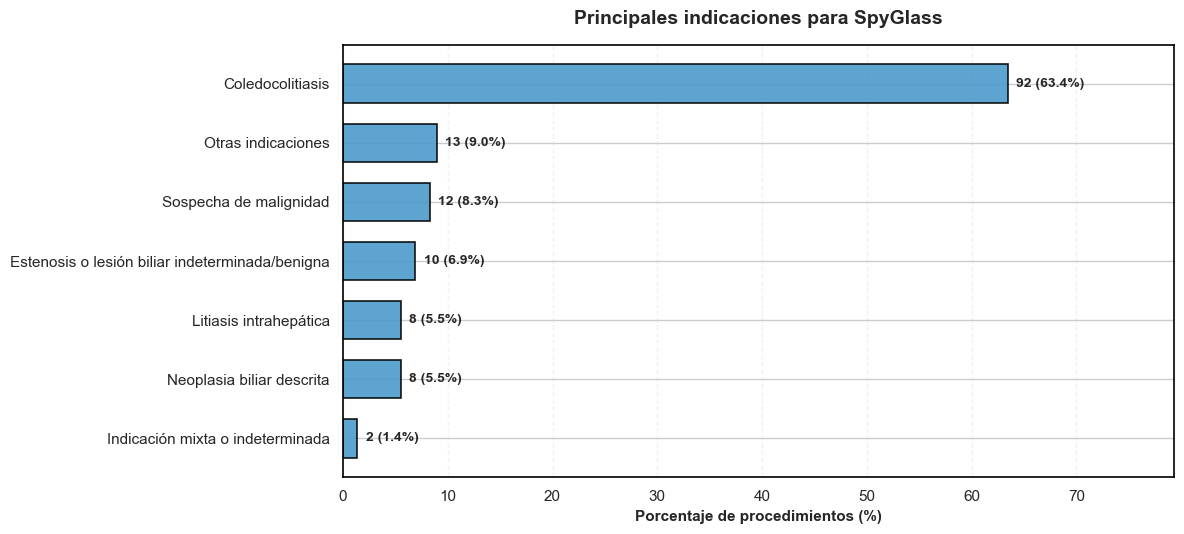

In [12]:
resumen_plot = resumen_indicaciones.sort_values(
    "Porcentaje (%)",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 5.5))

bars = ax.barh(
    resumen_plot["Indicación"],
    resumen_plot["Porcentaje (%)"],
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9,
    height=0.65
)

for bar, count, percentage in zip(
    bars,
    resumen_plot["Procedimientos"],
    resumen_plot["Porcentaje (%)"]
):
    ax.text(
        bar.get_width() + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Principales indicaciones para SpyGlass",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Porcentaje de procedimientos (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel("")
ax.set_xlim(0, resumen_plot["Porcentaje (%)"].max() * 1.25)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La **coledocolitiasis** fue la principal indicación para la realización de SpyGlass, con 92 procedimientos (63.4%), representando casi dos tercios de la muestra. Las demás indicaciones presentaron frecuencias considerablemente menores, destacándose otras indicaciones (9.0%), sospecha de malignidad (8.3%) y estenosis o lesiones biliares indeterminadas o benignas (6.9%).

La litiasis intrahepática y las neoplasias biliares descritas representaron cada una el 5.5% de los procedimientos, mientras que las indicaciones mixtas o indeterminadas fueron las menos frecuentes (1.4%).

En general, los resultados evidencian un **predominio de la coledocolitiasis como motivo registrado para la realización de SpyGlass**, aunque también se identificaron indicaciones relacionadas con alteraciones estructurales de la vía biliar y sospechas de malignidad. Estas categorías corresponden a las indicaciones clínicas consignadas en la base de datos y no necesariamente a diagnósticos confirmados.

## 4. Hallazgos endoscópicos 

En esta sección se describen los principales hallazgos endoscópicos registrados durante los procedimientos, con el propósito de identificar las alteraciones observadas con mayor frecuencia y caracterizar los resultados de la exploración de la vía biliar.

### 4.1. Características endoscópicas observadas

Se analiza la frecuencia de las principales características morfológicas registradas durante la exploración endoscópica, con el propósito de identificar los hallazgos más frecuentes en los procedimientos.

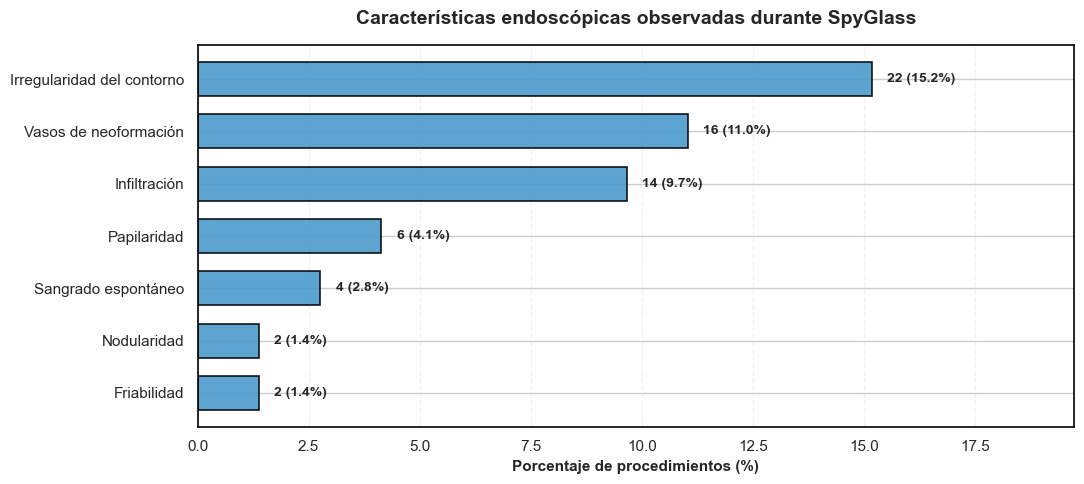

In [13]:
variables_endoscopicas = {
    "VASOS DE NEOFORMACION": "Vasos de neoformación",
    "FRIABILIDAD": "Friabilidad",
    "IRREGULARIDAD DEL CONTORNO": "Irregularidad del contorno",
    "SANGRADO ESPONTANEO": "Sangrado espontáneo",
    "PAPILARIDAD": "Papilaridad",
    "INFILTRACION": "Infiltración",
    "NODULARIDAD": "Nodularidad"
}

hallazgos_normalizados = (
    df_spyglass[list(variables_endoscopicas)]
    .apply(lambda columna: columna.astype("string").str.strip().str.upper())
)

resumen_hallazgos = pd.DataFrame({
    "Hallazgo": list(variables_endoscopicas.values()),
    "Procedimientos": [
        hallazgos_normalizados[columna].eq("SI").sum()
        for columna in variables_endoscopicas
    ],
    "Sin información": [
        (~hallazgos_normalizados[columna].isin(["SI", "NO"])).sum()
        for columna in variables_endoscopicas
    ]
})

resumen_hallazgos["Porcentaje (%)"] = (
    resumen_hallazgos["Procedimientos"] / len(df_spyglass) * 100
)

resumen_hallazgos = resumen_hallazgos.sort_values(
    "Porcentaje (%)",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    resumen_hallazgos["Hallazgo"],
    resumen_hallazgos["Porcentaje (%)"],
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9,
    height=0.65
)

for bar, count, percentage in zip(
    bars,
    resumen_hallazgos["Procedimientos"],
    resumen_hallazgos["Porcentaje (%)"]
):
    ax.text(
        bar.get_width() + 0.35,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Características endoscópicas observadas durante SpyGlass",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Porcentaje de procedimientos (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel("")
ax.set_xlim(0, resumen_hallazgos["Porcentaje (%)"].max() * 1.3)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La **irregularidad del contorno** fue la característica endoscópica registrada con mayor frecuencia, identificándose en 22 procedimientos (15.2%), seguida de los vasos de neoformación en 16 (11.0%) y la infiltración en 14 (9.7%).

Las demás características fueron menos frecuentes: papilaridad (4.1%), sangrado espontáneo (2.8%), nodularidad (1.4%) y friabilidad (1.4%).

En general, los hallazgos evaluados estuvieron ausentes en la mayoría de los procedimientos. No obstante, se identificaron alteraciones morfológicas en una proporción de los registros, principalmente relacionadas con irregularidad del contorno, vasos de neoformación e infiltración. Estas características describen la apariencia endoscópica observada y **no permiten, por sí solas, establecer un diagnóstico de malignidad**.

### 4.2. Aspecto de la superficie

Se examinan las descripciones del aspecto de la superficie registradas durante SpyGlass, con el propósito de identificar alteraciones morfológicas adicionales a las características endoscópicas analizadas anteriormente.

In [15]:
col_superficie = "ASPECTO DE LA SUPERFICE"

superficie_normalizada = (
    df_spyglass[col_superficie]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(r"\s+", " ", regex=True)
)

valores_sin_descripcion = [
    "NO",
    "NO DESCRIBE",
    "NO DESCRITO",
    "NO APLICA",
    ""
]

estado_superficie = pd.Series(
    np.where(
        superficie_normalizada.isna(),
        "Sin información",
        np.where(
            superficie_normalizada.isin(valores_sin_descripcion),
            "Sin descripción específica",
            "Con descripción específica"
        )
    ),
    index=df_spyglass.index
)

resumen_superficie = (
    estado_superficie
    .value_counts()
    .rename_axis("Estado del registro")
    .reset_index(name="Procedimientos")
)

resumen_superficie["Porcentaje (%)"] = (
    resumen_superficie["Procedimientos"] / len(df_spyglass) * 100
)

display(
    resumen_superficie.style
    .format({
        "Procedimientos": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Estado del registro"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        "Tabla 7. Disponibilidad de descripciones del aspecto de la superficie"
    )
    .hide(axis="index")
)

Estado del registro,Procedimientos,Porcentaje (%)
Sin descripción específica,109,75.17%
Con descripción específica,28,19.31%
Sin información,8,5.52%


La mayoría de los procedimientos, **109 (75.2%)**, no presentó una descripción específica del aspecto de la superficie, mientras que 28 (19.3%) incluyeron observaciones morfológicas y 8 (5.5%) no contaron con información registrada.

Estos resultados evidencian una limitación en el nivel de detalle de los registros endoscópicos, dado que únicamente una proporción reducida de los procedimientos dispone de descripciones específicas. Es importante señalar que la ausencia de estas descripciones no implica necesariamente que la superficie examinada presentara características normales.

### 4.3. Características de los cálculos biliares

Se describen las características de los cálculos biliares registrados durante los procedimientos SpyGlass, considerando su tamaño, número y localización anatómica. El análisis se realiza según la disponibilidad de información de cada variable, debido a que no todos los procedimientos cuentan con estos datos.

#### 4.3.1 Tamaño de los cálculos

Estadístico,Valor
Registros disponibles,76.00
Media,17.08
Desviación estándar,5.62
Mediana,15.00
Primer cuartil (Q1),15.00
Tercer cuartil (Q3),20.00
Mínimo,12.00
Máximo,40.00


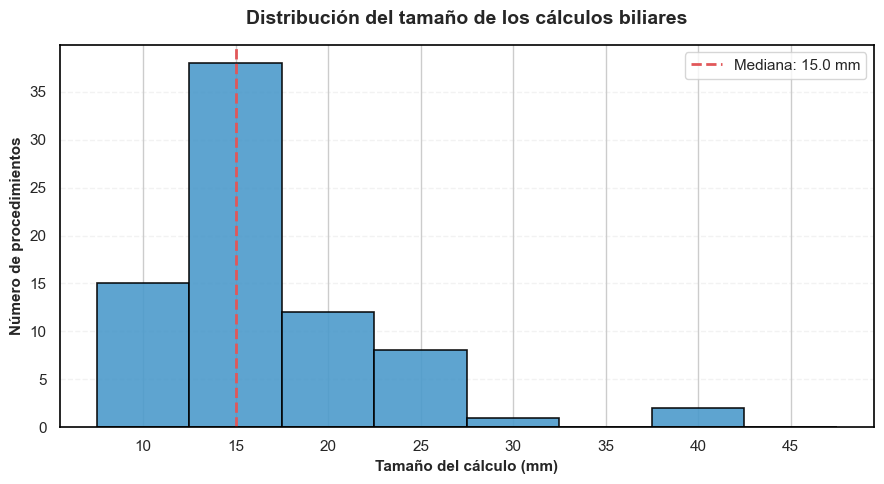

In [16]:
tamano_calculos = pd.to_numeric(
    df_spyglass["TAMAÑO DE CALCULO MM"],
    errors="coerce"
).dropna()

resumen_tamano = pd.DataFrame({
    "Estadístico": [
        "Registros disponibles",
        "Media",
        "Desviación estándar",
        "Mediana",
        "Primer cuartil (Q1)",
        "Tercer cuartil (Q3)",
        "Mínimo",
        "Máximo"
    ],
    "Valor": [
        len(tamano_calculos),
        tamano_calculos.mean(),
        tamano_calculos.std(),
        tamano_calculos.median(),
        tamano_calculos.quantile(0.25),
        tamano_calculos.quantile(0.75),
        tamano_calculos.min(),
        tamano_calculos.max()
    ]
})

display(
    resumen_tamano.style
    .format({"Valor": "{:.2f}"})
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Estadístico"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption("Tabla 8. Estadísticos descriptivos del tamaño de los cálculos biliares")
    .hide(axis="index")
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    tamano_calculos,
    bins=np.arange(7.5, 47.6, 5),
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

ax.axvline(
    tamano_calculos.median(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {tamano_calculos.median():.1f} mm"
)

ax.set_title(
    "Distribución del tamaño de los cálculos biliares",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Tamaño del cálculo (mm)", fontsize=11, fontweight="bold")
ax.set_ylabel("Número de procedimientos", fontsize=11, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

El tamaño de los cálculos biliares se analizó en **76 procedimientos con información disponible**, encontrándose una media de 17.08 mm y una mediana de 15 mm. El 50% central de los registros presentó tamaños entre 15 y 20 mm, con valores que oscilaron entre 12 y 40 mm.

El histograma muestra una **concentración de los tamaños alrededor de los 15 mm**, con una distribución ligeramente asimétrica hacia la derecha debido a la presencia de algunos valores elevados, especialmente de 40 mm.

Estos resultados permiten caracterizar el tamaño de los cálculos registrados durante SpyGlass. Sin embargo, deben interpretarse considerando que esta información estuvo disponible únicamente en **76 de los 145 procedimientos (52.4%)**.

#### 4.3.2. Número de cálculos biliares

Se describe la cantidad de cálculos registrada por procedimiento, considerando únicamente los casos con información disponible. 

In [17]:
numero_calculos = pd.to_numeric(
    df_spyglass["N_CALCULOS"],
    errors="coerce"
).dropna()

resumen_numero_calculos = (
    numero_calculos
    .value_counts()
    .sort_index()
    .rename_axis("Número de cálculos")
    .reset_index(name="Procedimientos")
)

resumen_numero_calculos["Porcentaje (%)"] = (
    resumen_numero_calculos["Procedimientos"] / len(numero_calculos) * 100
)

display(
    resumen_numero_calculos.style
    .format({
        "Número de cálculos": "{:.0f}",
        "Procedimientos": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        f"Tabla 9. Número de cálculos biliares registrados (n = {len(numero_calculos)})"
    )
    .hide(axis="index")
)

Número de cálculos,Procedimientos,Porcentaje (%)
1,1,4.17%
2,11,45.83%
3,9,37.50%
4,2,8.33%
5,1,4.17%


En los **24** procedimientos con información disponible, el número de cálculos más frecuente fue de dos (45.8%), seguido de tres (37.5%). En conjunto, estas categorías representaron el **83.3%** de los registros analizados.

Los procedimientos con uno, cuatro o cinco cálculos fueron menos frecuentes. Estos resultados muestran un predominio de múltiples cálculos entre los casos documentados. Sin embargo, debido a que esta variable solo cuenta con información en **24 de los 145 procedimientos (16.6%)**, los resultados deben interpretarse con cautela y no generalizarse a toda la muestra.

#### 4.3.3. Ubicación anatómica de los cálculos biliares

Se analiza la distribución anatómica de los cálculos registrados durante los procedimientos, considerando las diferentes localizaciones descritas en la base de datos. Para facilitar su interpretación, se revisan las variantes de escritura y los registros que incluyen múltiples ubicaciones.

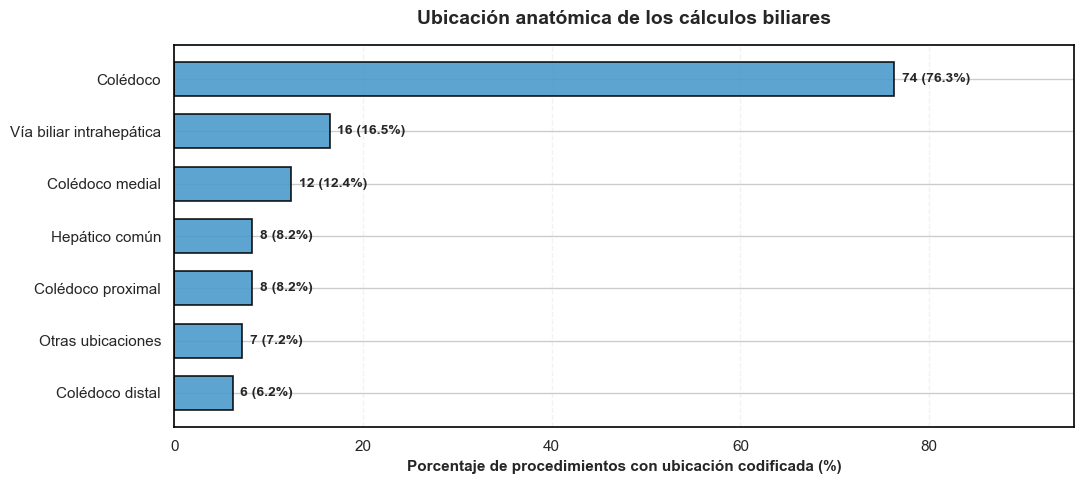

In [21]:
ubicaciones = {
    "UBIC_COLEDOCO": "Colédoco",
    "UBIC_COLEDOCO_PROXIMAL": "Colédoco proximal",
    "UBIC_COLEDOCO_MEDIAL": "Colédoco medial",
    "UBIC_COLEDOCO_DISTAL": "Colédoco distal",
    "UBIC_HEPATICO_COMUN": "Hepático común",
    "UBIC_INTRAHEPATICO": "Vía biliar intrahepática",
    "UBIC_OTRA": "Otras ubicaciones"
}

n_ubicaciones = (
    df_spyglass["UBIC_COLEDOCO"].notna()
    & df_spyglass["UBIC_NO_APLICA"].ne(1)
).sum()

resumen_ubicaciones = pd.DataFrame({
    "Ubicación": list(ubicaciones.values()),
    "Procedimientos": [
        df_spyglass[columna].eq(1).sum()
        for columna in ubicaciones
    ]
})

resumen_ubicaciones["Porcentaje (%)"] = (
    resumen_ubicaciones["Procedimientos"] / n_ubicaciones * 100
)

resumen_ubicaciones = resumen_ubicaciones.sort_values(
    "Porcentaje (%)",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    resumen_ubicaciones["Ubicación"],
    resumen_ubicaciones["Porcentaje (%)"],
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9,
    height=0.65
)

for bar, count, percentage in zip(
    bars,
    resumen_ubicaciones["Procedimientos"],
    resumen_ubicaciones["Porcentaje (%)"]
):
    ax.text(
        bar.get_width() + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Ubicación anatómica de los cálculos biliares",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Porcentaje de procedimientos con ubicación codificada (%)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel("")
ax.set_xlim(0, resumen_ubicaciones["Porcentaje (%)"].max() * 1.25)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

El colédoco fue la localización anatómica más frecuente de los cálculos biliares, registrada en **74 procedimientos (76.3%)**, seguido de la vía biliar intrahepática, con 16 (16.5%), y el colédoco medial, con 12 (12.4%).

Las demás localizaciones presentaron frecuencias menores, incluyendo el hepático común y el colédoco proximal (8.2% cada uno), otras ubicaciones (7.2%) y el colédoco distal (6.2%). Estos resultados evidencian un **predominio de la localización de los cálculos en el colédoco**.

:::{admonition} Consideración metodológica
:class: note

El análisis se realizó sobre **97 procedimientos con información anatómica aplicable**, excluyendo 9 registros clasificados como «No aplica» y 39 sin información codificada.

La ausencia de información no constituye necesariamente un error de registro, dado que algunos procedimientos pueden no presentar cálculos biliares o tener indicaciones clínicas diferentes.

Las categorías anatómicas no son mutuamente excluyentes, por lo que un mismo procedimiento puede presentar múltiples localizaciones y la suma de los porcentajes puede superar el 100%.
:::

### 4.4. Características de las estenosis biliares

Se examina la información disponible sobre las estenosis biliares, con el propósito de describir su frecuencia y localización anatómica en los procedimientos SpyGlass. Se consideran las categorías registradas y las posibles limitaciones para identificar la presencia o ausencia de estenosis.

#### 4.4.1. Registro de estenosis biliares

Se examina la disponibilidad de información sobre las estenosis biliares, diferenciando los procedimientos con localización anatómica documentada, aquellos con ausencia explícita de estenosis y los registros sin información suficiente.

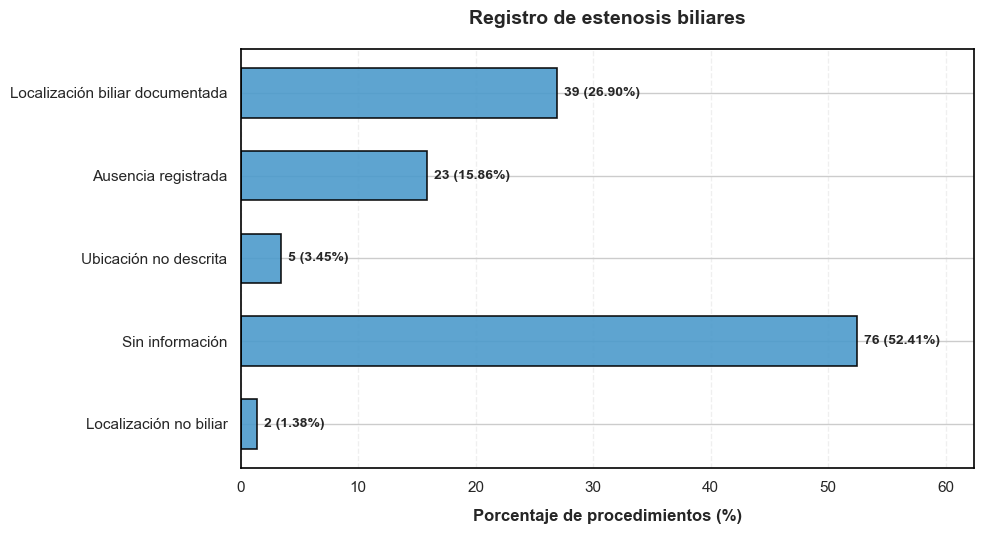

In [62]:
ubicaciones = (
    df_spyglass["UBICACION DE LA ESTENOSIS"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.upper()
)

ubicaciones = (
    ubicaciones
    .str.replace("Á", "A", regex=False)
    .str.replace("É", "E", regex=False)
    .str.replace("Í", "I", regex=False)
    .str.replace("Ó", "O", regex=False)
    .str.replace("Ú", "U", regex=False)
)

categorias = pd.Series(
    "Localización biliar documentada",
    index=df_spyglass.index
)

categorias.loc[ubicaciones.isna()] = "Sin información"
categorias.loc[ubicaciones.eq("NO").fillna(False)] = "Ausencia registrada"
categorias.loc[ubicaciones.eq("NO DESCRIBE").fillna(False)] = "Ubicación no descrita"

no_biliares = ubicaciones.str.contains(
    r"WIRSUNG|ESOFAGO",
    na=False
)

categorias.loc[no_biliares] = "Localización no biliar"

orden = [
    "Localización biliar documentada",
    "Ausencia registrada",
    "Ubicación no descrita",
    "Sin información",
    "Localización no biliar"
]

conteos = categorias.value_counts().reindex(orden, fill_value=0)
porcentajes = conteos / len(df_spyglass) * 100

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    orden,
    porcentajes.values,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    height=0.6,
    alpha=0.9
)

for bar, count, pct in zip(bars, conteos.values, porcentajes.values):
    ax.text(
        bar.get_width() + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({pct:.2f}%)",
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.invert_yaxis()

ax.set_xlim(0, porcentajes.max() + 10)

ax.set_title(
    "Registro de estenosis biliares",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Porcentaje de procedimientos (%)",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

De los **145 procedimientos analizados**, 39 (26.90%) presentaron una localización anatómica de estenosis biliar documentada, mientras que en 23 (15.86%) se registró explícitamente su ausencia.

Por otra parte, 76 procedimientos (52.41%) no contaron con información en esta variable y 5 (3.45%) fueron clasificados como «NO DESCRIBE». Adicionalmente, se identificaron 2 registros (1.38%) con localizaciones anatómicas no biliares.

La elevada proporción de registros sin información limita la estimación de la frecuencia real de estenosis biliares, por lo que los resultados deben interpretarse como una descripción de la información documentada.

#### 4.4.2. Localización anatómica de las estenosis biliares

Se describe la distribución anatómica de las estenosis biliares con localización documentada. Dado que algunas descripciones incluyen el compromiso de múltiples segmentos, las categorías anatómicas no se consideran mutuamente excluyentes.

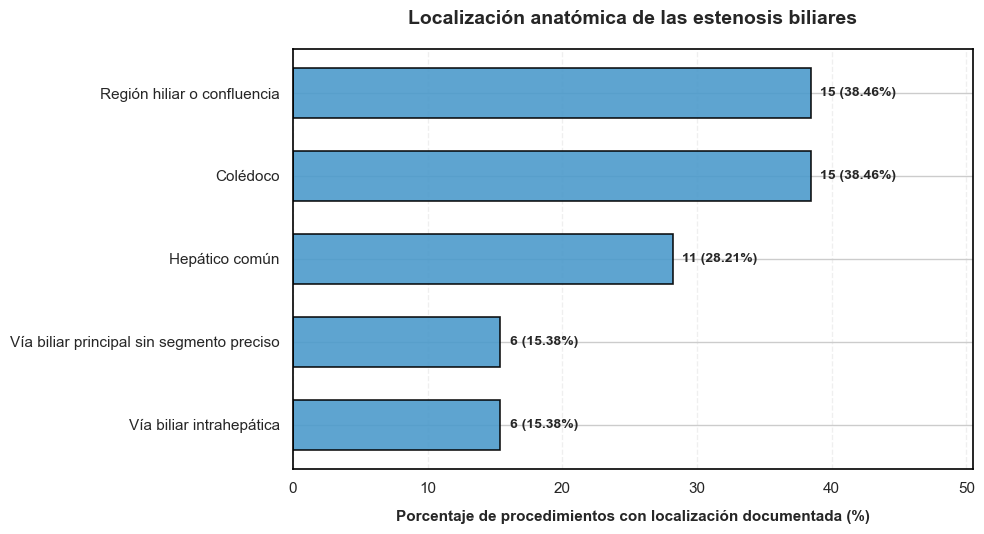

In [64]:
resumen_estenosis = resumen_estenosis.sort_values(
    "Procedimientos",
    ascending=True
)

resumen_estenosis["Porcentaje (%)"] = (
    resumen_estenosis["Procedimientos"] / len(ubicaciones_validas) * 100
)

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    resumen_estenosis["Localización anatómica"],
    resumen_estenosis["Porcentaje (%)"],
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    height=0.6,
    alpha=0.9
)

for bar, count, pct in zip(
    bars,
    resumen_estenosis["Procedimientos"],
    resumen_estenosis["Porcentaje (%)"]
):
    ax.text(
        bar.get_width() + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({pct:.2f}%)",
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlim(
    0,
    resumen_estenosis["Porcentaje (%)"].max() + 12
)

ax.set_title(
    "Localización anatómica de las estenosis biliares",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Porcentaje de procedimientos con localización documentada (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

Entre los **39 procedimientos con localización biliar documentada**, el colédoco y la región hiliar o confluencia fueron las localizaciones más frecuentes, con 15 procedimientos cada una (38.46%). Les siguió el hepático común, con 11 procedimientos (28.21%).

La vía biliar intrahepática y la vía biliar principal sin segmento preciso se identificaron en 6 procedimientos cada una (15.38%).

Dado que algunas estenosis comprometieron múltiples segmentos anatómicos, las categorías no son mutuamente excluyentes y sus porcentajes pueden sumar más del 100%.

## 5. Procedimientos terapéuticos realizados 

En esta sección se describen las intervenciones terapéuticas documentadas durante los procedimientos, con énfasis en el uso de prótesis biliares y la dilatación de papila. Se examina la frecuencia de estas intervenciones y las categorías registradas, considerando las limitaciones de interpretación de algunas variables.

### 5.1 Uso de prótesis biliar y dilatación de papila

In [23]:
columnas_terapeuticas = {
    "USO DE PROTESIS BILIAR": "Uso de prótesis biliar",
    "DILATACION DE PAPILA": "Dilatación de papila"
}

resumen_terapeuticos = []

for columna, variable in columnas_terapeuticas.items():
    conteos = (
        df_spyglass[columna]
        .astype("string")
        .str.strip()
        .str.upper()
        .value_counts(dropna=False)
    )

    for categoria, frecuencia in conteos.items():
        resumen_terapeuticos.append({
            "Variable": variable,
            "Categoría": str(categoria),
            "Procedimientos": frecuencia,
            "Porcentaje (%)": frecuencia / len(df_spyglass) * 100
        })

resumen_terapeuticos = pd.DataFrame(resumen_terapeuticos)

display(
    resumen_terapeuticos.style
    .format({
        "Procedimientos": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Variable", "Categoría"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        "Tabla 10. Distribución del uso de prótesis biliar y dilatación de papila (n = 145)"
    )
    .hide(axis="index")
)

Variable,Categoría,Procedimientos,Porcentaje (%)
Uso de prótesis biliar,SI,104,71.72%
Uso de prótesis biliar,NO,38,26.21%
Uso de prótesis biliar,PREVIA,1,0.69%
Uso de prótesis biliar,DREN PERCUTANEO A LIBRE DRENAJE,1,0.69%
Uso de prótesis biliar,"SI, PROTESIS PANCREATICA",1,0.69%
Dilatación de papila,NO,112,77.24%
Dilatación de papila,SI,33,22.76%


El uso de prótesis biliar se registró como «Sí» en **104 procedimientos (71.7%)**, mientras que 38 (26.2%) fueron clasificados como «No». Adicionalmente, se identificaron tres registros con categorías específicas que requieren una interpretación diferenciada.

Por su parte, la dilatación de papila se documentó en **33 procedimientos (22.8%)**, mientras que en 112 (77.2%) no se registró su realización.

:::{admonition} Consideración metodológica
:class: note

La categoría «PREVIA» no permite establecer si la prótesis estaba presente antes del procedimiento o si fue colocada durante el acto médico analizado. Asimismo, los registros correspondientes a drenaje percutáneo y prótesis pancreática se mantienen diferenciados para evitar clasificarlos incorrectamente como colocaciones de prótesis biliares.

Por tanto, los resultados describen las categorías registradas, sin asumir que todos los casos corresponden a intervenciones realizadas durante el procedimiento actual.
:::

### 5.2. Tiempo quirúrgico

Se analiza la duración de los procedimientos SpyGlass mediante las principales medidas descriptivas, con el propósito de caracterizar los tiempos registrados durante la intervención y explorar su variabilidad.

In [24]:
tiempo_quirurgico = pd.to_numeric(
    df_spyglass["TIEMPO QUIRÚRGICO EN MINUTOS"],
    errors="coerce"
)

resumen_tiempo = pd.DataFrame({
    "Indicador": [
        "Procedimientos con información",
        "Procedimientos sin información",
        "Media (min)",
        "Desviación estándar (min)",
        "Mediana (min)",
        "Primer cuartil (min)",
        "Tercer cuartil (min)",
        "Mínimo (min)",
        "Máximo (min)"
    ],
    "Valor": [
        tiempo_quirurgico.notna().sum(),
        tiempo_quirurgico.isna().sum(),
        tiempo_quirurgico.mean(),
        tiempo_quirurgico.std(),
        tiempo_quirurgico.median(),
        tiempo_quirurgico.quantile(0.25),
        tiempo_quirurgico.quantile(0.75),
        tiempo_quirurgico.min(),
        tiempo_quirurgico.max()
    ]
})

display(
    resumen_tiempo.style
    .format({"Valor": "{:.2f}"})
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Indicador"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption("Tabla 11. Estadísticas descriptivas del tiempo quirúrgico")
    .hide(axis="index")
)

Indicador,Valor
Procedimientos con información,145.00
Procedimientos sin información,0.00
Media (min),50.20
Desviación estándar (min),21.55
Mediana (min),50.00
Primer cuartil (min),30.00
Tercer cuartil (min),60.00
Mínimo (min),20.00
Máximo (min),150.00


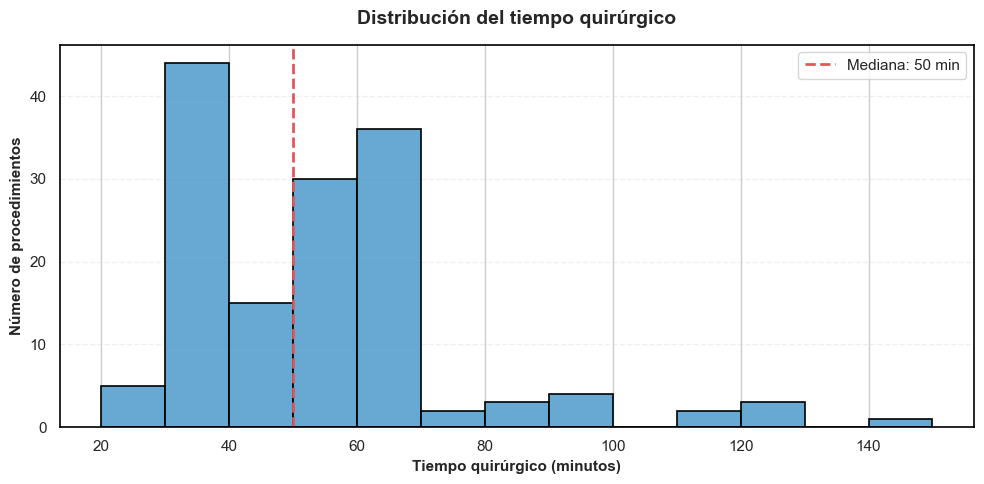

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    tiempo_quirurgico.dropna(),
    bins=13,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1.2,
    alpha=0.85,
    ax=ax
)

ax.axvline(
    tiempo_quirurgico.median(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {tiempo_quirurgico.median():.0f} min"
)

ax.set_title(
    "Distribución del tiempo quirúrgico",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Tiempo quirúrgico (minutos)",
    fontsize=11,
    fontweight="bold"
)

ax.set_ylabel(
    "Número de procedimientos",
    fontsize=11,
    fontweight="bold"
)

ax.legend(frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

El tiempo quirúrgico se registró en la totalidad de los **145 procedimientos**, con una media de 50.20 minutos y una mediana de 50 minutos. El 50% central de los procedimientos presentó duraciones entre 30 y 60 minutos, con un mínimo de 20 y un máximo de 150 minutos.

El histograma muestra una **mayor concentración de procedimientos entre los 30 y 70 minutos**, con algunos registros de duración elevada que generan una prolongación de la distribución hacia la derecha. La desviación estándar de 21.55 minutos refleja la variabilidad existente entre los tiempos registrados.

En general, los resultados permiten caracterizar la duración de los procedimientos realizados. No obstante, los tiempos elevados no deben interpretarse automáticamente como anomalías, ya que podrían estar relacionados con diferencias en la complejidad de las intervenciones.

## 6. Biopsias dirigidas y resultados histopatológicos

En esta sección se analiza la frecuencia de toma de biopsias durante los procedimientos SpyGlass, el número de muestras obtenidas y los principales resultados histopatológicos registrados, con el propósito de caracterizar la información diagnóstica disponible.

### 6.1. Frecuencia de toma de biopsias

Se describe la proporción de procedimientos en los que se registró toma de biopsia, considerando las categorías disponibles en la base de datos.

In [27]:
conteos_biopsia = (
    df_spyglass["BIOPSIA_TOMADA"]
    .map({
        1: "Sí",
        0: "No"
    })
    .fillna("Sin información")
    .value_counts()
    .reindex(["Sí", "No", "Sin información"], fill_value=0)
)

resumen_biopsias = (
    conteos_biopsia
    .rename_axis("Toma de biopsia")
    .reset_index(name="Procedimientos")
)

resumen_biopsias["Porcentaje (%)"] = (
    resumen_biopsias["Procedimientos"] / len(df_spyglass) * 100
)

display(
    resumen_biopsias.style
    .format({
        "Procedimientos": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Toma de biopsia"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption("Tabla 12. Frecuencia de toma de biopsias durante SpyGlass (n = 145)")
    .hide(axis="index")
)

Toma de biopsia,Procedimientos,Porcentaje (%)
Sí,33,22.76%
No,111,76.55%
Sin información,1,0.69%


La toma de biopsias se registró en **33 de los 145 procedimientos (22.8%)**, mientras que en 111 (76.6%) no se documentó su realización. Adicionalmente, un procedimiento (0.7%) no presentó información disponible sobre esta variable.

Estos resultados muestran que la toma de biopsias se realizó en una proporción minoritaria de los procedimientos analizados, lo cual debe interpretarse considerando que SpyGlass también se utiliza con fines terapéuticos y para la evaluación de patologías que no necesariamente requieren biopsia.

### 6.2. Número de biopsias obtenidas

Se describe la cantidad de biopsias registradas por procedimiento, considerando los casos en los que se dispone de un valor numérico. Los registros con descripciones no cuantificables se identifican por separado para evitar interpretaciones incorrectas.

In [28]:
numero_biopsias = pd.to_numeric(
    df_spyglass.loc[
        df_spyglass["BIOPSIA_TOMADA"].eq(1),
        "N_BIOPSIAS"
    ],
    errors="coerce"
)

biopsias_validas = numero_biopsias.dropna()

resumen_numero_biopsias = pd.DataFrame({
    "Indicador": [
        "Procedimientos con biopsia",
        "Con cantidad numérica",
        "Sin cantidad numérica",
        "Media",
        "Desviación estándar",
        "Mediana",
        "Primer cuartil",
        "Tercer cuartil",
        "Mínimo",
        "Máximo"
    ],
    "Valor": [
        len(numero_biopsias),
        len(biopsias_validas),
        numero_biopsias.isna().sum(),
        biopsias_validas.mean(),
        biopsias_validas.std(),
        biopsias_validas.median(),
        biopsias_validas.quantile(0.25),
        biopsias_validas.quantile(0.75),
        biopsias_validas.min(),
        biopsias_validas.max()
    ]
})

display(
    resumen_numero_biopsias.style
    .format({"Valor": "{:.2f}"})
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Indicador"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption("Tabla 13. Estadísticas descriptivas del número de biopsias")
    .hide(axis="index")
)

Indicador,Valor
Procedimientos con biopsia,33.00
Con cantidad numérica,28.00
Sin cantidad numérica,5.00
Media,4.89
Desviación estándar,3.15
Mediana,4.00
Primer cuartil,2.00
Tercer cuartil,8.00
Mínimo,1.00
Máximo,12.00


De los **33 procedimientos en los que se registró toma de biopsias**, 28 (84.8%) contaron con información numérica sobre la cantidad de muestras obtenidas, mientras que 5 (15.2%) presentaron descripciones no cuantificables.

Entre los procedimientos con información numérica, se obtuvo una media de **4.89 biopsias por procedimiento**, con una mediana de 4 y una desviación estándar de 3.15. El 50% central de los registros presentó entre 2 y 8 biopsias, con cantidades que oscilaron entre 1 y 12.

Estos resultados muestran cierta variabilidad en el número de biopsias obtenidas. Sin embargo, la descripción corresponde únicamente a los **28 procedimientos con cantidades numéricas disponibles**, sin asumir valores para los registros descritos como «MÚLTIPLES» o sin cantidad especificada.

### 6.3. Resultados histopatológicos

Se describen los resultados histopatológicos registrados durante los procedimientos, con el propósito de identificar los principales hallazgos diagnósticos obtenidos mediante biopsias dirigidas. El análisis considera la disponibilidad de información y las categorías presentes en la base de datos.

In [31]:
categorias_patologia = {
    "NO_MALIGNO": "No maligno",
    "NEOPLASICO": "Neoplásico"
}

resultados_biopsia = (
    df_spyglass.loc[
        df_spyglass["BIOPSIA_TOMADA"].eq(1),
        "RESULTADO_PATOLOGICO"
    ]
    .map(categorias_patologia)
    .fillna("Sin resultado disponible")
)

resumen_patologia = (
    resultados_biopsia
    .value_counts()
    .reindex(
        ["No maligno", "Neoplásico", "Sin resultado disponible"],
        fill_value=0
    )
    .rename_axis("Resultado histopatológico")
    .reset_index(name="Procedimientos")
)

resumen_patologia["Porcentaje (%)"] = (
    resumen_patologia["Procedimientos"] / len(resultados_biopsia) * 100
)

display(
    resumen_patologia.style
    .format({
        "Procedimientos": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Resultado histopatológico"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        "Tabla 14. Resultados histopatológicos en procedimientos con biopsia (n = 33)"
    )
    .hide(axis="index")
)

Resultado histopatológico,Procedimientos,Porcentaje (%)
No maligno,22,66.67%
Neoplásico,10,30.30%
Sin resultado disponible,1,3.03%


De los **33 procedimientos con toma de biopsia registrada**, 22 (66.67%) presentaron resultados histopatológicos no malignos, mientras que 10 (30.30%) fueron clasificados como neoplásicos. El procedimiento restante (3.03%) no contó con un resultado histopatológico disponible.

Por tanto, los resultados no malignos fueron los más frecuentes entre los procedimientos con biopsia, seguidos de los hallazgos neoplásicos.

### 6.4. Hallazgos histopatológicos específicos

Se describen los hallazgos histopatológicos específicos registrados en los procedimientos con biopsia, considerando que un mismo procedimiento puede presentar más de un hallazgo.

In [32]:
hallazgos_patologicos = {
    "PAT_NEOPLASIA": "Neoplasia",
    "PAT_NEGATIVO_MALIGNIDAD": "Negativo para malignidad",
    "PAT_INFLAMACION": "Inflamación",
    "PAT_FIBROSIS": "Fibrosis",
    "PAT_OTRO_BENIGNO": "Otros hallazgos benignos",
    "PAT_OTRA": "Otros hallazgos"
}

df_biopsias = df_spyglass.loc[df_spyglass["BIOPSIA_TOMADA"].eq(1)]

tabla_15 = pd.DataFrame({
    "Hallazgo histopatológico": list(hallazgos_patologicos.values()),
    "Procedimientos": [
        df_biopsias[columna].eq(1).sum()
        for columna in hallazgos_patologicos
    ]
})

tabla_15["Porcentaje (%)"] = (
    tabla_15["Procedimientos"] / len(df_biopsias) * 100
)

display(
    tabla_15.style
    .format({
        "Procedimientos": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Hallazgo histopatológico"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        "Tabla 15. Hallazgos histopatológicos específicos en procedimientos con biopsia (n = 33)"
    )
    .hide(axis="index")
)

Hallazgo histopatológico,Procedimientos,Porcentaje (%)
Neoplasia,10,30.30%
Negativo para malignidad,9,27.27%
Inflamación,12,36.36%
Fibrosis,5,15.15%
Otros hallazgos benignos,7,21.21%
Otros hallazgos,0,0.00%


Entre los **33 procedimientos con toma de biopsia**, la inflamación fue el hallazgo histopatológico más frecuente, registrado en 12 procedimientos (36.36%), seguida de neoplasia en 10 (30.30%) y resultados negativos para malignidad en 9 (27.27%).

También se identificaron otros hallazgos benignos en 7 procedimientos (21.21%) y fibrosis en 5 (15.15%). No se registraron hallazgos en la categoría «Otros hallazgos».

Dado que un mismo procedimiento puede presentar varios hallazgos histopatológicos, las categorías no son mutuamente excluyentes y sus porcentajes no deben sumarse.

## 7. Desenlaces clínicos y complicaciones

En esta sección se describen las complicaciones y los desenlaces clínicos registrados en los procedimientos, incluyendo pancreatitis, sangrado, perforación, reintervenciones biliares, resolución del cuadro, fracaso terapéutico y mortalidad.

### 7.1. Complicaciones registradas

Se analiza la frecuencia de pancreatitis, sangrado y perforación, considerando las categorías y la disponibilidad de información de cada variable.

In [34]:
complicaciones = {
    "PANCREATITIS": "Pancreatitis",
    "SANGRADO": "Sangrado",
    "PERFORACION (30 DIAS)": "Perforación (30 días)"
}

tabla_16 = pd.DataFrame({
    "Complicación": list(complicaciones.values()),
    "Sí": [
        df_spyglass[columna].eq("SI").sum()
        for columna in complicaciones
    ],
    "No": [
        df_spyglass[columna].eq("NO").sum()
        for columna in complicaciones
    ],
    "Sin información": [
        df_spyglass[columna].isna().sum()
        for columna in complicaciones
    ]
})

tabla_16["Porcentaje (%)"] = (
    tabla_16["Sí"] / len(df_spyglass) * 100
)

display(
    tabla_16.style
    .format({
        "Sí": "{:.0f}",
        "No": "{:.0f}",
        "Sin información": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Complicación"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        "Tabla 16. Complicaciones registradas en procedimientos SpyGlass (n = 145)"
    )
    .hide(axis="index")
)

Complicación,Sí,No,Sin información,Porcentaje (%)
Pancreatitis,7,137,1,4.83%
Sangrado,3,141,1,2.07%
Perforación (30 días),0,144,1,0.00%


Entre los **145 procedimientos analizados**, la pancreatitis fue la complicación registrada con mayor frecuencia, con 7 casos (4.83%), seguida del sangrado, con 3 casos (2.07%). No se registraron casos de perforación durante los 30 días contemplados por la variable.

Las tres variables presentaron un procedimiento sin información disponible.

### 7.2. Reintervenciones biliares

Se describe la frecuencia de reintervenciones biliares registradas en la base de datos, considerando la disponibilidad de información y las categorías documentadas.

In [36]:
reintervenciones = (
    df_spyglass["REINTERVENCIONES BILIARES"]
    .astype("string")
    .str.strip()
    .str.upper()
)

tabla_17 = (
    reintervenciones
    .map({"SI": "Sí", "NO": "No"})
    .fillna("Sin información")
    .value_counts()
    .reindex(["Sí", "No", "Sin información"], fill_value=0)
    .rename_axis("Reintervención biliar")
    .reset_index(name="Procedimientos")
)

tabla_17["Porcentaje (%)"] = (
    tabla_17["Procedimientos"] / len(df_spyglass) * 100
)

display(
    tabla_17.style
    .format({
        "Procedimientos": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Reintervención biliar"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        "Tabla 17. Reintervenciones biliares registradas (n = 145)"
    )
    .hide(axis="index")
)

Reintervención biliar,Procedimientos,Porcentaje (%)
Sí,49,33.79%
No,96,66.21%
Sin información,0,0.00%


De los **145 procedimientos analizados**, 49 (33.79%) presentaron reintervenciones biliares registradas, mientras que en 96 (66.21%) no se documentaron reintervenciones.

Por tanto, aproximadamente uno de cada tres procedimientos presentó una reintervención biliar registrada.

### 7.3. Resolución del cuadro clínico

Se describe la frecuencia de resolución del cuadro clínico registrada en los procedimientos, considerando las categorías disponibles en la base de datos.

In [38]:
resolucion = (
    df_spyglass["RESOLUCION DEL CUADRO"]
    .astype("string")
    .str.strip()
    .str.upper()
)

tabla_18 = (
    resolucion
    .map({"SI": "Sí", "NO": "No"})
    .fillna("Sin información")
    .value_counts()
    .reindex(["Sí", "No", "Sin información"], fill_value=0)
    .rename_axis("Resolución del cuadro clínico")
    .reset_index(name="Procedimientos")
)

tabla_18["Porcentaje (%)"] = (
    tabla_18["Procedimientos"] / len(df_spyglass) * 100
)

display(
    tabla_18.style
    .format({
        "Procedimientos": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Resolución del cuadro clínico"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        "Tabla 18. Resolución del cuadro clínico en procedimientos SpyGlass (n = 145)"
    )
    .hide(axis="index")
)

Resolución del cuadro clínico,Procedimientos,Porcentaje (%)
Sí,124,85.52%
No,21,14.48%
Sin información,0,0.00%


De los **145 procedimientos analizados**, 124 (85.52%) registraron resolución del cuadro clínico, mientras que 21 (14.48%) no presentaron resolución.

Estos resultados muestran que la resolución del cuadro clínico fue el desenlace más frecuente entre los procedimientos evaluados.

### 7.4. Fracaso terapéutico

Se describe la frecuencia de fracaso terapéutico registrada en los procedimientos SpyGlass, con el propósito de caracterizar este desenlace clínico y su distribución en la población analizada.

In [40]:
fracaso = (
    df_spyglass["FRACASO TERAPEUTICO"]
    .astype("string")
    .str.strip()
    .str.upper()
)

tabla_19 = (
    fracaso
    .map({"SI": "Sí", "NO": "No"})
    .fillna("Sin información")
    .value_counts()
    .reindex(["Sí", "No", "Sin información"], fill_value=0)
    .rename_axis("Fracaso terapéutico")
    .reset_index(name="Procedimientos")
)

tabla_19["Porcentaje (%)"] = (
    tabla_19["Procedimientos"] / len(df_spyglass) * 100
)

display(
    tabla_19.style
    .format({
        "Procedimientos": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Fracaso terapéutico"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        "Tabla 19. Fracaso terapéutico en procedimientos SpyGlass (n = 145)"
    )
    .hide(axis="index")
)

Fracaso terapéutico,Procedimientos,Porcentaje (%)
Sí,28,19.31%
No,117,80.69%
Sin información,0,0.00%


De los **145 procedimientos analizados**, 28 (19.31%) registraron fracaso terapéutico, mientras que en 117 (80.69%) no se documentó este desenlace.

Por tanto, el fracaso terapéutico se registró en aproximadamente uno de cada cinco procedimientos evaluados.

#### 7.4.1. Relación entre fracaso terapéutico y resolución del cuadro clínico

Se analiza la distribución conjunta de ambos desenlaces mediante una matriz de calor, con el propósito de visualizar su correspondencia e identificar los procedimientos que presentan clasificaciones diferentes.

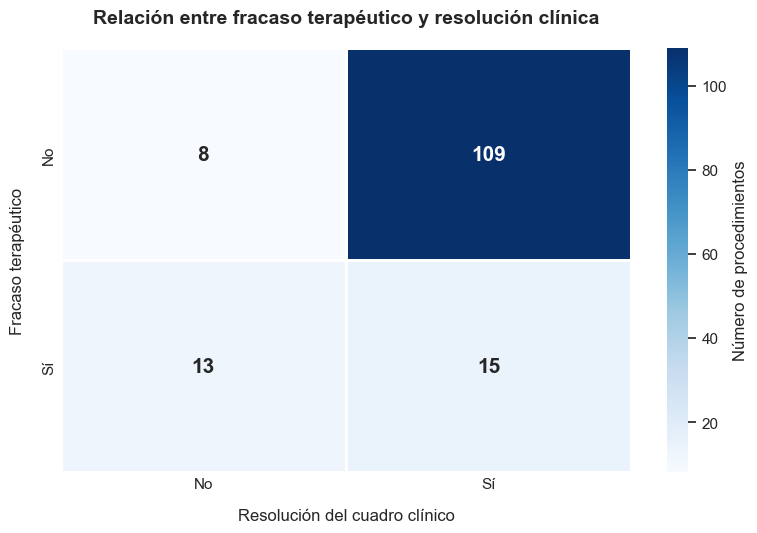

In [43]:
tabla_cruce = pd.crosstab(
    df_spyglass["FRACASO TERAPEUTICO"],
    df_spyglass["RESOLUCION DEL CUADRO"]
)

tabla_cruce = tabla_cruce.reindex(
    index=["NO", "SI"],
    columns=["NO", "SI"],
    fill_value=0
)

tabla_cruce.index = ["No", "Sí"]
tabla_cruce.columns = ["No", "Sí"]

fig, ax = plt.subplots(figsize=(8, 5.5))

sns.heatmap(
    tabla_cruce,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=2,
    linecolor="white",
    cbar_kws={"label": "Número de procedimientos"},
    annot_kws={"size": 15, "weight": "bold"},
    ax=ax
)

ax.set_xlabel("Resolución del cuadro clínico", fontsize=12, labelpad=12)
ax.set_ylabel("Fracaso terapéutico", fontsize=12, labelpad=12)
ax.set_title(
    "Relación entre fracaso terapéutico y resolución clínica",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.tick_params(axis="both", labelsize=11, length=0)
plt.tight_layout()
plt.show()

La matriz de calor muestra que la combinación más frecuente correspondió a procedimientos sin fracaso terapéutico y con resolución del cuadro clínico (109 casos).

Sin embargo, se identificaron 15 procedimientos con fracaso terapéutico y resolución clínica, así como 8 procedimientos sin fracaso terapéutico que tampoco presentaron resolución. Adicionalmente, 13 procedimientos registraron fracaso terapéutico sin resolución clínica.

Estos resultados evidencian que ambos desenlaces no presentan una correspondencia exacta en los registros analizados.

### 7.5. Mortalidad y supervivencia

Se describe la mortalidad registrada en los procedimientos SpyGlass, considerando las categorías disponibles y la calidad de la información. El análisis se limita a los desenlaces documentados en la base de datos, sin asumir un periodo de seguimiento que no esté explícitamente establecido.

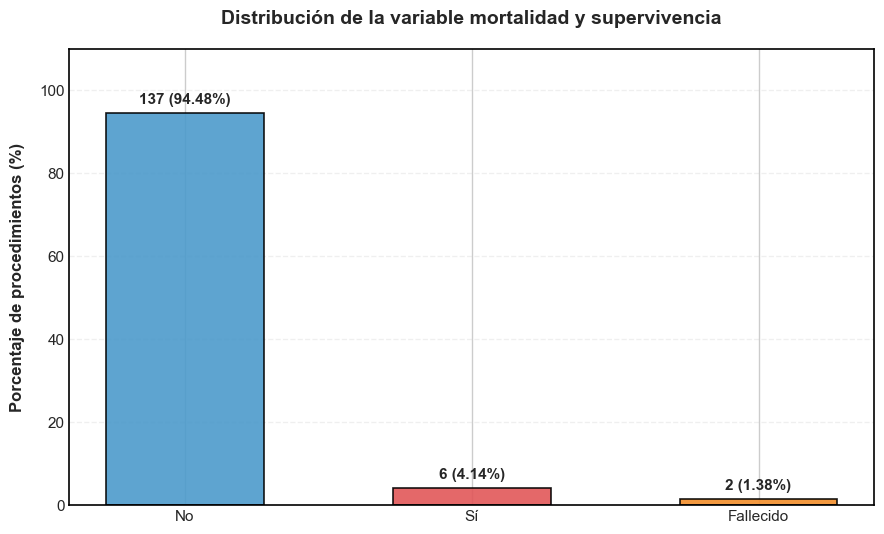

In [49]:
mortalidad = (
    df_spyglass["MORTALIDAD Y SUPERVIVENCIA"]
    .astype("string")
    .str.strip()
    .str.upper()
)

conteos = mortalidad.value_counts().reindex(
    ["NO", "SI", "FALLECIDO"],
    fill_value=0
)

etiquetas = ["No", "Sí", "Fallecido"]
porcentajes = conteos / len(df_spyglass) * 100

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    etiquetas,
    porcentajes.values,
    color=["#4C9ACB", "#E15759", "#F28E2B"],
    edgecolor="black",
    linewidth=1.2,
    width=0.55,
    alpha=0.9
)

for bar, count, pct in zip(
    bars,
    conteos.values,
    porcentajes.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{count} ({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Distribución de la variable mortalidad y supervivencia",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("")
ax.set_ylabel(
    "Porcentaje de procedimientos (%)",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

ax.set_ylim(0, 110)

ax.tick_params(
    axis="both",
    labelsize=11,
    length=0
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

La variable de mortalidad y supervivencia presentó **137 procedimientos (94.48%)** clasificados como «NO», **6 (4.14%)** como «SI» y **2 (1.38%)** como «FALLECIDO». La categoría «NO» fue ampliamente predominante entre los 145 procedimientos analizados.

Aunque las categorías «SI» y «FALLECIDO» podrían representar el mismo desenlace, se mantienen separadas debido a que su equivalencia no ha sido confirmada.

:::{admonition} Consideración metodológica
:class: note

La interpretación de las categorías «SI» y «FALLECIDO» requiere validación con el equipo clínico o el diccionario de datos. Adicionalmente, la base de datos no especifica el periodo de seguimiento ni permite establecer si los fallecimientos estuvieron directamente relacionados con el procedimiento SpyGlass. Por tanto, no es posible realizar un análisis de supervivencia temporal ni atribuir los fallecimientos al procedimiento.

:::

### 7.6. Recurrencia de la ictericia

Se describe la frecuencia de recurrencia de la ictericia registrada en los procedimientos.

In [51]:
recurrencia = (
    df_spyglass["RECURRENCIA DE LA ICTERICIA"]
    .astype("string")
    .str.strip()
    .str.upper()
)

tabla_20 = (
    recurrencia
    .map({"SI": "Sí", "NO": "No"})
    .fillna("Sin información")
    .value_counts()
    .reindex(["Sí", "No", "Sin información"], fill_value=0)
    .rename_axis("Recurrencia de la ictericia")
    .reset_index(name="Procedimientos")
)

tabla_20["Porcentaje (%)"] = (
    tabla_20["Procedimientos"] / len(df_spyglass) * 100
)

display(
    tabla_20.style
    .format({
        "Procedimientos": "{:.0f}",
        "Porcentaje (%)": "{:.2f}%"
    })
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #D9E2F3",
        "padding": "8px"
    })
    .set_properties(
        subset=["Recurrencia de la ictericia"],
        **{"text-align": "left"}
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "9px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "15px"),
                ("font-weight", "bold"),
                ("color", "#17365D"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption(
        "Tabla 20. Recurrencia de la ictericia en procedimientos SpyGlass (n = 145)"
    )
    .hide(axis="index")
)

Recurrencia de la ictericia,Procedimientos,Porcentaje (%)
Sí,18,12.41%
No,127,87.59%
Sin información,0,0.00%


De los **145 procedimientos analizados**, 18 (12.41%) registraron recurrencia de la ictericia, mientras que en 127 (87.59%) no se documentó este desenlace.

Por tanto, la recurrencia de la ictericia se presentó en una proporción minoritaria de los procedimientos evaluados.

## 8. Concordancia diagnóstica exploratoria

Esta sección explora la relación entre la indicación clínica del procedimiento, los hallazgos endoscópicos y los resultados histopatológicos registrados. El propósito es identificar patrones de correspondencia entre estas fuentes de información, sin asumir que constituyen diagnósticos equivalentes ni estimar medidas de precisión diagnóstica sin un estándar de referencia validado.

### 8.1. Indicación clínica y resultado histopatológico

Se examina la distribución de los resultados histopatológicos según la indicación principal agrupada, considerando únicamente los procedimientos con biopsia y resultado disponible.

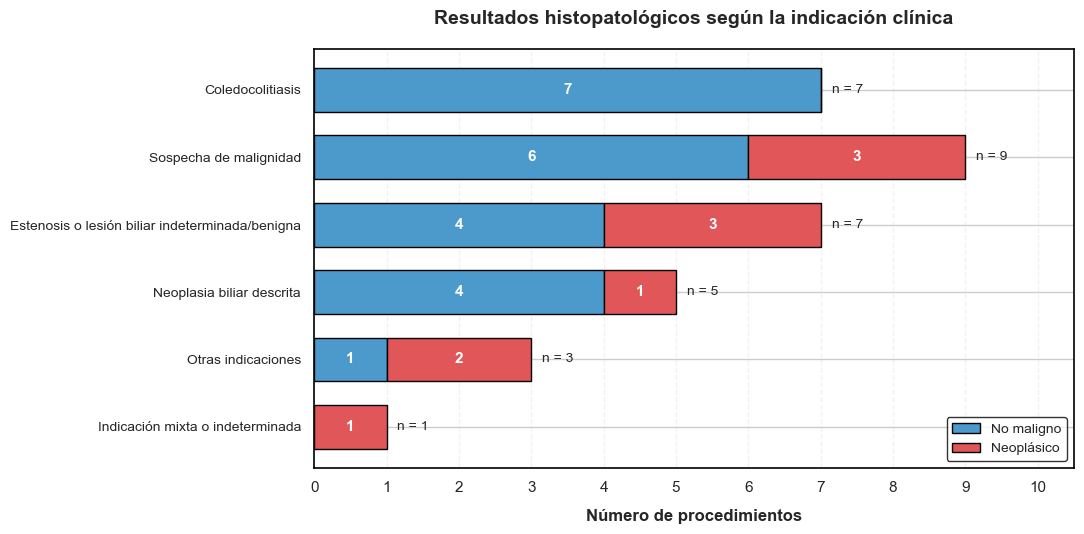

In [55]:
df_concordancia = df_spyglass.loc[
    df_spyglass["BIOPSIA_TOMADA"].eq(1)
    & df_spyglass["RESULTADO_PATOLOGICO"].isin(
        ["NO_MALIGNO", "NEOPLASICO"]
    )
].copy()

tabla_concordancia = pd.crosstab(
    df_concordancia["INDICACION_AGRUPADA"],
    df_concordancia["RESULTADO_PATOLOGICO"]
)

tabla_concordancia = tabla_concordancia.reindex(
    columns=["NO_MALIGNO", "NEOPLASICO"],
    fill_value=0
)

tabla_concordancia = tabla_concordancia.sort_values(
    by=["NO_MALIGNO", "NEOPLASICO"],
    ascending=False
)

etiquetas = tabla_concordancia.index.tolist()
no_maligno = tabla_concordancia["NO_MALIGNO"].values
neoplasico = tabla_concordancia["NEOPLASICO"].values
totales = no_maligno + neoplasico

fig, ax = plt.subplots(figsize=(11, 5.5))

y = np.arange(len(etiquetas))

ax.barh(
    y,
    no_maligno,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1,
    height=0.65,
    label="No maligno"
)

ax.barh(
    y,
    neoplasico,
    left=no_maligno,
    color="#E15759",
    edgecolor="black",
    linewidth=1,
    height=0.65,
    label="Neoplásico"
)

for i, (nm, neo, total) in enumerate(
    zip(no_maligno, neoplasico, totales)
):
    if nm > 0:
        ax.text(
            nm / 2,
            i,
            str(nm),
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color="white"
        )

    if neo > 0:
        ax.text(
            nm + neo / 2,
            i,
            str(neo),
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color="white"
        )

    ax.text(
        total + 0.15,
        i,
        f"n = {total}",
        va="center",
        fontsize=10
    )

ax.set_yticks(y)
ax.set_yticklabels(etiquetas, fontsize=10)
ax.invert_yaxis()

ax.set_xlim(0, max(totales) + 1.5)
ax.set_xticks(np.arange(0, max(totales) + 2, 1))

ax.set_title(
    "Resultados histopatológicos según la indicación clínica",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Número de procedimientos",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel("")

ax.legend(
    loc="lower right",
    frameon=True,
    edgecolor="black",
    fontsize=10
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

Entre los **32 procedimientos con resultado histopatológico disponible**, la sospecha de malignidad fue la indicación más frecuente, con 9 procedimientos, de los cuales 6 presentaron resultados no malignos y 3 neoplásicos.

En los procedimientos indicados por coledocolitiasis, los 7 resultados fueron no malignos. Por su parte, las estenosis o lesiones biliares indeterminadas/benignas registraron 4 resultados no malignos y 3 neoplásicos, mientras que en los procedimientos con neoplasia biliar descrita se identificaron 4 resultados no malignos y 1 neoplásico.

En general, los resultados no malignos predominaron en la mayoría de las indicaciones clínicas. Sin embargo, se identificaron hallazgos neoplásicos en distintas categorías, lo que evidencia que la indicación inicial no siempre se corresponde con el resultado histopatológico obtenido.

### 8.2. Hallazgos endoscópicos y resultados histopatológicos

Se explora la distribución de los resultados histopatológicos según los hallazgos endoscópicos registrados durante SpyGlass, con el propósito de identificar posibles patrones de correspondencia entre las características visualizadas y los resultados de las biopsias.

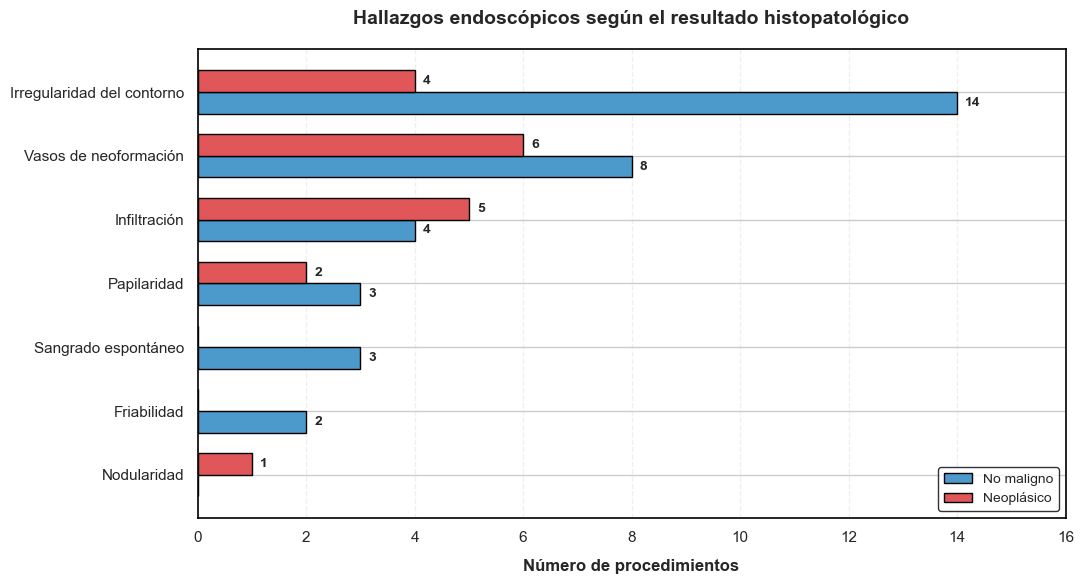

In [58]:
tabla_grafico = tabla_hallazgos[
    ["No maligno", "Neoplásico"]
].copy()

tabla_grafico["Total"] = tabla_grafico.sum(axis=1)

tabla_grafico = tabla_grafico.sort_values(
    "Total",
    ascending=True
)

etiquetas = tabla_grafico.index
y = np.arange(len(etiquetas))
altura = 0.34

fig, ax = plt.subplots(figsize=(11, 6))

bars_no = ax.barh(
    y - altura / 2,
    tabla_grafico["No maligno"],
    height=altura,
    color="#4C9ACB",
    edgecolor="black",
    linewidth=1,
    label="No maligno"
)

bars_neo = ax.barh(
    y + altura / 2,
    tabla_grafico["Neoplásico"],
    height=altura,
    color="#E15759",
    edgecolor="black",
    linewidth=1,
    label="Neoplásico"
)

for bars in [bars_no, bars_neo]:
    for bar in bars:
        valor = bar.get_width()

        if valor > 0:
            ax.text(
                valor + 0.15,
                bar.get_y() + bar.get_height() / 2,
                f"{int(valor)}",
                ha="left",
                va="center",
                fontsize=10,
                fontweight="bold"
            )

ax.set_yticks(y)
ax.set_yticklabels(etiquetas, fontsize=11)

ax.set_xlim(0, tabla_grafico[["No maligno", "Neoplásico"]].max().max() + 2)

ax.set_title(
    "Hallazgos endoscópicos según el resultado histopatológico",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Número de procedimientos",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel("")

ax.legend(
    loc="lower right",
    frameon=True,
    edgecolor="black",
    fontsize=10
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

Entre los **32 procedimientos con resultado histopatológico disponible**, la irregularidad del contorno fue el hallazgo endoscópico más frecuente, presente en 14 procedimientos con resultado no maligno y 4 con resultado neoplásico.

Los vasos de neoformación se registraron en 8 procedimientos con resultado no maligno y 6 neoplásicos, mientras que la infiltración se identificó en 4 y 5 procedimientos, respectivamente.

La papilaridad se observó en ambos grupos, mientras que la friabilidad y el sangrado espontáneo únicamente se registraron en procedimientos con resultados no malignos. Por su parte, la nodularidad se identificó en un procedimiento con resultado neoplásico.

Estos resultados muestran que varios hallazgos endoscópicos aparecen tanto en procedimientos con histopatología neoplásica como no maligna. Por tanto, su presencia aislada no permite establecer una clasificación diagnóstica definitiva.

Dado que un procedimiento puede presentar múltiples hallazgos, las frecuencias de las categorías no son mutuamente excluyentes.

## 9. Conclusiones y consideraciones metodológicas

### 9.1. Principales hallazgos del análisis exploratorio

El análisis exploratorio permitió caracterizar **145 procedimientos SpyGlass** registrados en la Clínica de la Costa, describiendo sus características demográficas y clínicas, las principales indicaciones, los hallazgos endoscópicos, las intervenciones documentadas y los desenlaces clínicos.

Entre los principales resultados se destacan:

- **Características de la población:** predominó el sexo femenino (63.45%), con una mediana de edad de 54 años. La mayoría de los procedimientos correspondió a pacientes procedentes de Atlántico y La Guajira.

- **Indicaciones clínicas:** la coledocolitiasis fue la indicación principal más frecuente (63.45%), seguida de otras condiciones biliares, incluidas sospechas de malignidad y estenosis.

- **Hallazgos endoscópicos:** la irregularidad del contorno y los vasos de neoformación estuvieron entre los hallazgos morfológicos más frecuentes. En los procedimientos con ubicación anatómica de cálculos codificada, predominó el colédoco.

- **Intervenciones registradas:** el uso de prótesis biliar se documentó frecuentemente, aunque algunas categorías requieren aclaración para establecer si corresponden a prótesis preexistentes o intervenciones realizadas durante el procedimiento. El tiempo quirúrgico presentó una mediana de 50 minutos.

- **Biopsias e histopatología:** se registró toma de biopsias en 33 procedimientos (22.76%). De estos, 22 presentaron resultados no malignos, 10 neoplásicos y uno no contó con resultado disponible.

- **Desenlaces clínicos:** la pancreatitis (4.83%) y el sangrado (2.07%) fueron las complicaciones registradas. Se documentó resolución del cuadro clínico en el 85.52% de los procedimientos, fracaso terapéutico en el 19.31%, reintervenciones biliares en el 33.79% y recurrencia de la ictericia en el 12.41%.

- **Exploración diagnóstica:** se identificaron diferencias entre las indicaciones clínicas, los hallazgos endoscópicos y los resultados histopatológicos. Sin embargo, los análisis realizados son descriptivos y no permiten establecer medidas formales de concordancia o precisión diagnóstica.

### 9.2. Alcance respecto a los objetivos del protocolo

El EDA permitió abordar descriptivamente los objetivos relacionados con la caracterización de la población, las indicaciones clínicas, los hallazgos endoscópicos, las intervenciones documentadas, las biopsias y los desenlaces clínicos.

El objetivo de concordancia diagnóstica se abordó de manera exploratoria mediante comparaciones entre la indicación clínica, los hallazgos endoscópicos y la histopatología. No obstante, su evaluación formal requiere definir criterios de concordancia y disponer de un diagnóstico de referencia validado.

Por tanto, el análisis exploratorio constituye una primera aproximación a los objetivos del protocolo, pero no reemplaza los análisis estadísticos posteriores ni la validación clínica de las variables.

### 9.3. Limitaciones y consideraciones metodológicas

El análisis presenta las siguientes limitaciones:

- **Unidad de análisis:** los 145 registros corresponden a procedimientos. Al no disponer de un identificador único de paciente, no es posible determinar si existen procedimientos repetidos en una misma persona ni garantizar independencia entre observaciones.

- **Información faltante:** algunas variables presentan registros incompletos o categorías sin información suficiente. No se realizaron imputaciones que pudieran introducir supuestos clínicos no sustentados.

- **Registro de intervenciones:** ciertas categorías, como «PREVIA» en el uso de prótesis biliar, requieren validación clínica. Asimismo, la base no permite identificar de manera independiente todas las intervenciones contempladas en el protocolo.

- **Mortalidad y supervivencia:** las categorías «SI» y «FALLECIDO» requieren confirmación de su equivalencia. Tampoco se dispone de información suficiente sobre el tiempo de seguimiento para realizar un análisis de supervivencia.

- **Concordancia diagnóstica:** la ausencia de un estándar de referencia definido y las diferencias entre las variables disponibles impiden estimar formalmente sensibilidad, especificidad o concordancia diagnóstica.

- **Alcance descriptivo:** los resultados corresponden a los procedimientos incluidos en la base institucional y no permiten establecer relaciones causales ni generalizar automáticamente los hallazgos a otras poblaciones.